# V-JEPA 2 from scratch 🎬→🧠→🤖
### Self-supervised video model → action-conditioned world model → zero-shot robot planning

*Paper: **V-JEPA 2: Self-Supervised Video Models Enable Understanding, Prediction and Planning** - Assran, Bardes, Fan, Garrido, ... LeCun, Rabbat, Ballas (Meta FAIR, 2025), [arXiv:2506.09985](https://arxiv.org/abs/2506.09985).*

This notebook builds V-JEPA 2 **piece by piece**, the way you would if you had to write it yourself. Every step has: **an intuition → the math (equation numbers are the paper's) → code you can run → a check that proves the code does what the text says.** Figures marked *"Fig. N (paper)"* are cropped from the paper itself; others come from the papers it builds on (ViT, MAE, I-JEPA, BYOL, RoPE, V-JEPA) or from Meta's MIT-licensed repo. All credit to the original authors.

<p align="center"><img src="images/p_fig1_overview.png" width="900"><br><sub>Fig. 1 (paper) - the whole story: pretrain on internet video, then either probe/align for understanding or post-train on 62 h of robot data for planning.</sub></p>

| step | question | what we build |
|---|---|---|
| 1 | Why predict in *latent space* instead of pixels? | a measurable toy argument |
| 2 | How does a video become tokens? | 3D **tubelet** patch embedding (2×16×16) |
| 3 | How does a transformer know *where/when* a token is? | **3D-RoPE** |
| 4 | What do we hide? | **multi-block masking** (full temporal extent, ~90 % in the paper) |
| 5 | The encoder | a ViT over *visible* tokens only; parameter counts of ViT-L/H/g vs the paper |
| 6 | The predictor | visible tokens + learnable **mask tokens** → predict masked features |
| 7 | The target and the loss | **EMA encoder, stop-grad, L1 (Eq. 1)**, and what happens without them |
| 8 | Train the whole thing | tiny V-JEPA on synthetic video, then *frozen* probes |
| 9 | What makes it scale | warmup-constant-cooldown LR, progressive resolution, data, model size |
| 10 | **V-JEPA 2-AC**: add actions | frozen encoder + block-causal action-conditioned predictor (Eqs. 2-4) |
| 11 | **Planning** | goal-image **energy** (Eq. 5) + Cross-Entropy Method + MPC |
| 12 | The paper's results, limits, and what came next | tables, figures, honest caveats |

**Two scales, kept honest.** *Paper scale* numbers (1 B parameters, 22 M videos, 62 h of Droid robot data) are quoted from the paper and marked as such. *Toy scale* experiments (0.5 M-parameter encoder, 48×48 synthetic videos of a moving blob, CPU) are run here, so you can see each mechanism work end-to-end. Toy results demonstrate **mechanisms**, not the paper's accuracy numbers.

*Prerequisite:* what a transformer is. Plain PyTorch, CPU only.

In [1]:
import math, time, copy, random
import numpy as np, torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
torch.manual_seed(0); np.random.seed(0); random.seed(0)
torch.set_num_threads(max(1, torch.get_num_threads()))
plt.rcParams.update({"figure.dpi": 105, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25, "font.size": 9})
CHECKS = []
def check(name, ok, detail=""): CHECKS.append((name, bool(ok), detail)); print(("PASS " if ok else "FAIL ") + name + (f"   [{detail}]" if detail else ""))

## Step 1 - Why predict in latent space? 🎯

**The goal (paper §1).** Learn a *world model* from video: something that can understand a scene, predict what happens next, and eventually help an agent plan. The obvious recipe is *generative*: predict the next frame's **pixels** (video diffusion, autoregressive pixel models, VideoMAE-style reconstruction).

**The problem.** A real video is full of detail that nobody - not even a perfect model - can predict: the exact sparkle on each leaf, sensor noise, the precise texture of grass. A pixel loss forces the model to spend capacity on it, and (with MSE) averages over it into blur. The paper says it directly: JEPA "focuses on learning representations for predictable aspects of a scene (e.g., the trajectory of an object in motion) while ignoring unpredictable details that generative objectives emphasize".

<p align="center"><img src="images/r_ijepa_fig2.png" width="880"><br><sub>Fig. 2 (I-JEPA, Assran et al. 2023) - (a) joint-embedding: compare two views; (b) generative: reconstruct y from x *in pixel space* using a decoder; (c) **joint-embedding predictive**: predict the *embedding* of y from x, with a latent variable z telling the predictor *which* part to predict. V-JEPA 2 is (c).</sub></p>

**Our toy world** (used for the whole notebook): a coloured Gaussian blob moves in a straight line (8 possible directions, random speed) over a textured background, with 2 static distractor blobs and **per-frame pixel noise**. The only *predictable, meaningful* thing is the blob's trajectory. Let's measure how little of the pixel signal that is.

In [2]:
# ---------------- the toy world (this exact generator is reused in every later step) ----------------
H = W = 48; PT, PS = 2, 8; GH = GW = H // PS          # frame size, tubelet time-depth, spatial patch size
def gauss(pos, sig=3.0):                              # pos (B,T,2)=(x,y) -> (B,T,H,W) Gaussian blobs
    ys = torch.arange(H).float(); xs = torch.arange(W).float()
    dx = xs[None, None, :] - pos[:, :, 0:1]; dy = ys[None, None, :] - pos[:, :, 1:2]
    return torch.exp(-(dy[:, :, :, None] ** 2 + dx[:, :, None, :] ** 2) / (2 * sig ** 2))

def make_video(B, T=8, ang=None, speed=None, static=False, n_dist=2, noise=0.15, parts=False):
    ang = torch.randint(0, 8, (B,)) if ang is None else ang                    # direction class = k * 45 degrees
    sp = torch.empty(B).uniform_(1.0, 2.5) if speed is None else speed          # pixels / frame
    if static: sp = torch.zeros(B)                                              # static clip = an "image" (paper duplicates images into clips)
    th = ang.float() * math.pi / 4; v = torch.stack([th.cos(), th.sin()], 1) * sp[:, None]
    c = torch.empty(B, 2).uniform_(14, 34); col = torch.rand(B, 3) * .5 + .5
    t = torch.arange(T).float() - (T - 1) / 2
    pos = c[:, None, :] + t[None, :, None] * v[:, None, :]
    bg = .25 * torch.rand(B, 3, 1, H, W); nz = noise * torch.randn(B, 3, T, H, W); dist = 0
    for _ in range(n_dist):
        dp = torch.empty(B, 1, 2).uniform_(8, 40).expand(-1, T, -1); dc = torch.rand(B, 3) * .5 + .5
        dist = dist + gauss(dp)[:, None] * dc[:, :, None, None, None]
    blob = gauss(pos)[:, None] * col[:, :, None, None, None]
    vid = bg + nz + dist + blob
    return (vid, ang, pos) if not parts else (vid, ang, pos, dict(bg=bg, noise=nz, dist=dist, blob=blob, col=col))

vid, ang, pos, P = make_video(256, parts=True)
e_noise = (P["noise"] ** 2).sum((1, 2, 3, 4)).mean(); e_blob = (P["blob"] ** 2).sum((1, 2, 3, 4)).mean()
print(f"pixel energy per clip:  unpredictable noise = {e_noise:,.0f}    moving blob (the thing that matters) = {e_blob:,.0f}    ratio noise/blob = {e_noise / e_blob:.1f}x")

# an *oracle* next-frame pixel predictor knows the scene perfectly except the noise: its MSE can never go below the noise variance.
# How much does a pixel loss reward getting the TRAJECTORY right vs wrong?
def clean(pp): return P["bg"] + P["dist"] + gauss(pp)[:, None] * P["col"][:, :, None, None, None]     # noise-free frame with the blob at pp
true_clean = clean(pos); wrong_pos = 2 * pos[:, :1] - pos                          # reflect trajectory around the start (opposite direction)
still_pos = pos[:, :1].expand(-1, pos.shape[1], -1)                                # "nothing moves" predictor
m = lambda p: ((vid[:, :, 1:] - clean(p)[:, :, 1:]) ** 2).mean().item()
m_or, m_wr, m_st = m(pos), m(wrong_pos), m(still_pos)
print(f"next-frame pixel MSE:  oracle (right trajectory) {m_or:.5f} | static guess {m_st:.5f} | wrong direction {m_wr:.5f}")
print(f"noise-variance floor   {0.15 ** 2:.5f}   (nobody can go below it)")
print(f"-> the right trajectory lowers the pixel MSE by {100 * (m_wr - m_or) / m_wr:.0f}% relative to a wrong-direction guess, but {100 * 0.15 ** 2 / m_wr:.0f}% of what even the WRONG guess pays is irreducible noise.")
check("unpredictable noise carries more pixel energy than the object whose motion we care about", e_noise > e_blob, f"{e_noise / e_blob:.1f}x")
check("most of the pixel loss is irreducible noise: even a wrong-trajectory guess pays >50% noise floor", 0.15 ** 2 / m_wr > 0.5, f"{100 * 0.15 ** 2 / m_wr:.0f}%")

pixel energy per clip:  unpredictable noise = 1,245    moving blob (the thing that matters) = 393    ratio noise/blob = 3.2x
next-frame pixel MSE:  oracle (right trajectory) 0.02251 | static guess 0.03136 | wrong direction 0.03409
noise-variance floor   0.02250   (nobody can go below it)
-> the right trajectory lowers the pixel MSE by 34% relative to a wrong-direction guess, but 66% of what even the WRONG guess pays is irreducible noise.
PASS unpredictable noise carries more pixel energy than the object whose motion we care about   [3.2x]
PASS most of the pixel loss is irreducible noise: even a wrong-trajectory guess pays >50% noise floor   [66%]


**Reading this.** The learning signal that separates a model that understands the motion from one that doesn't is a *minority* of the pixel loss; the majority is noise floor that no model can remove (the numbers above). In real video the ratio is far worse (textures, lighting, compression). V-JEPA's answer: don't regress pixels; regress the **output of an encoder** that is itself being trained to keep what is predictable. We will *measure* in Step 8 that the trained encoder indeed throws the noise away.

> **V-JEPA vs V-JEPA 2.** V-JEPA (Bardes et al. 2024) introduced the video recipe. V-JEPA 2 keeps the objective and **scales it** (data 2 M→22 M videos, model 300 M→1 B params, longer training, higher resolution/longer clips - Step 9), then adds the action-conditioned stage (Steps 10-11).

## Step 2 - From video to tokens: tubelets 🧱

A transformer eats a **sequence of vectors**. ViT (Dosovitskiy et al. 2020) cuts an image into square patches and linearly embeds each one:

<p align="center"><img src="images/r_vit_fig1.png" width="700"><br><sub>Fig. 1 (ViT) - split into fixed-size patches, embed linearly, add position information, run a transformer encoder.</sub></p>

For video, V-JEPA 2 does the same in 3D: it cuts the clip into **tubelets** of size `2 × 16 × 16` (T × H × W) - 2 consecutive frames × a 16×16 pixel square - and embeds each with a *strided 3D convolution* (Table 12 in the paper: "Embedder: 2 × 16 × 16 strided conv"). A conv with kernel = stride = (2,16,16) is exactly "flatten each tubelet and apply one shared linear layer".

Why 2 frames per token? Neighbouring frames are nearly identical, so merging them halves the sequence length at almost no information cost; and the token itself already carries a little *motion* (difference between its two frames).

Our toy uses `2 × 8 × 8` tubelets on `8 × 48 × 48` clips → `4 × 6 × 6 = 144` tokens.

video (2, 3, 8, 48, 48) -> token grid (4, 6, 6) -> (2, 144, 96) = (batch, tokens, dim)
PASS Conv3d patch embed == unfold tubelets + one shared linear layer   [max err 4.8e-07]

paper setting                        frames   res   tokens
pretrain (primary phase)                 16   256     2048
cooldown 64 frames                       64   256     8192
cooldown 64 frames, 384 px               64   384    18432
V-JEPA 2-AC (one frame as image)          2   256      256
PASS 16x256x256 clip -> 2048 tokens (paper's 16-frame / 256 px setting)
PASS 64x384x384 clip -> 18432 tokens


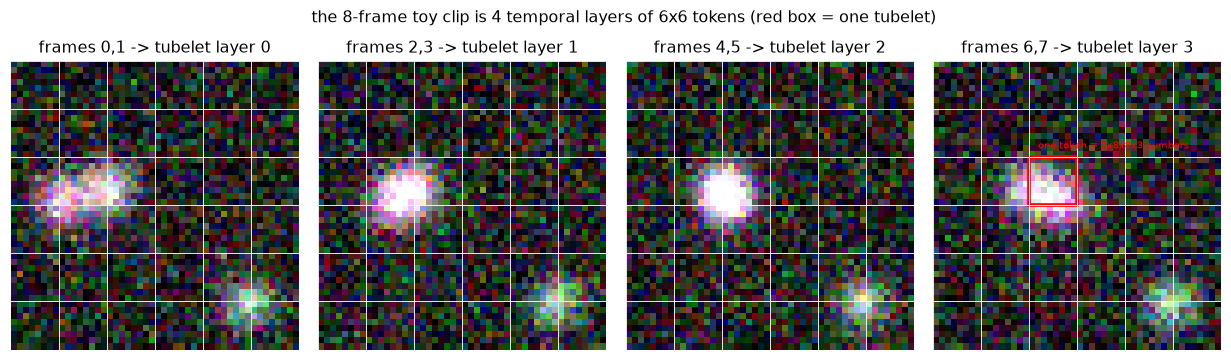

In [3]:
# ---- tubelet embedding: strided Conv3d  ==  "flatten each tubelet, shared linear layer" -----------
D = 96
embed = nn.Conv3d(3, D, (PT, PS, PS), stride=(PT, PS, PS))
v, _, _ = make_video(2)
tok = embed(v)                                           # (B, D, T/2, H/8, W/8)
GT = tok.shape[2]; tokens = tok.flatten(2).transpose(1, 2)
print("video", tuple(v.shape), "->", "token grid", tuple(tok.shape[2:]), "->", tuple(tokens.shape), "= (batch, tokens, dim)")

# same thing by hand: unfold into tubelets, flatten, matmul with the conv kernel
tub = v.unfold(2, PT, PT).unfold(3, PS, PS).unfold(4, PS, PS)           # (B,3,GT,GH,GW,PT,PS,PS)
tub = tub.permute(0, 2, 3, 4, 1, 5, 6, 7).reshape(2, -1, 3 * PT * PS * PS)
manual = tub @ embed.weight.reshape(D, -1).T + embed.bias
check("Conv3d patch embed == unfold tubelets + one shared linear layer", torch.allclose(manual, tokens, atol=1e-5), f"max err {(manual - tokens).abs().max():.1e}")

def n_tokens(T, Hh, Ww, pt=2, ps=16): return (T // pt) * (Hh // ps) * (Ww // ps)
rows = [("pretrain (primary phase)", 16, 256), ("cooldown 64 frames", 64, 256), ("cooldown 64 frames, 384 px", 64, 384), ("V-JEPA 2-AC (one frame as image)", 2, 256)]
print(f"\n{'paper setting':36s} {'frames':>6s} {'res':>5s} {'tokens':>8s}")
for n_, T_, r_ in rows: print(f"{n_:36s} {T_:6d} {r_:5d} {n_tokens(T_, r_, r_):8d}")
check("16x256x256 clip -> 2048 tokens (paper's 16-frame / 256 px setting)", n_tokens(16, 256, 256) == 2048)
check("64x384x384 clip -> 18432 tokens", n_tokens(64, 384, 384) == 18432)

# picture: which pixels become one token
vv, aa, pp = make_video(1, ang=torch.tensor([0]), speed=torch.tensor([2.2]))
fig, axs = plt.subplots(1, 4, figsize=(12, 3.3))
for i, ax in enumerate(axs):
    t0 = 2 * i; ax.imshow(vv[0, :, t0].permute(1, 2, 0).clamp(0, 1)); ax.set_title(f"frames {t0},{t0 + 1} -> tubelet layer {i}")
    for k in range(GH + 1): ax.axhline(k * PS - .5, color="w", lw=.6); ax.axvline(k * PS - .5, color="w", lw=.6)
    ax.grid(False); ax.axis("off")
ax.add_patch(Rectangle((2 * PS - .5, 2 * PS - .5), PS, PS, fill=False, ec="red", lw=2.5))
axs[-1].text(2 * PS + 1, 2 * PS - 2, "one token = 2x8x8x3 numbers", color="red", fontsize=7)
plt.suptitle("the 8-frame toy clip is 4 temporal layers of 6x6 tokens (red box = one tubelet)", y=1.02); plt.tight_layout(); plt.show()

## Step 3 - Telling the transformer *where* and *when*: 3D-RoPE 🧭

Self-attention is permutation-invariant: shuffle the tokens and nothing changes, so we must inject position. Older V-JEPA used absolute sin-cos embeddings **added** to the input. V-JEPA 2 uses **RoPE** (Su et al. 2021), which instead **rotates** the query and key vectors by an angle proportional to the position:

`q'_m = R(mθ) q_m`, `k'_n = R(nθ) k_n`  ⟹  `q'_m · k'_n = q_m · R((n−m)θ) k_n`

so the attention score depends only on the **relative offset** `n − m` - which is what you want for "the thing 2 patches to the left". The paper reports that 3D-RoPE "helps stabilize training for the largest models".

<p align="center"><img src="images/r_rope_fig1.png" width="760"><br><sub>Fig. 1 (RoFormer) - rotate each (x1,x2) pair of the query/key by m·θ. Pairs use different θ (frequencies).</sub></p>

**The 3D extension (paper §2.1):** split the feature dimension of each head into **three roughly equal segments** - one for time, one for height, one for width - and apply ordinary 1D RoPE to each segment using that axis' coordinate.

Our implementation: for head-dim `hd`, axis chunk `d = ⌊hd/3⌋` (rounded to even), frequencies `θ_i = 10000^(−2i/d)`.

PASS RoPE: score(q at t, k at t+2) is the same for t=3, 10, 100 (depends only on offset)   [-5.72017 -5.72017 -5.72017]
PASS RoPE: ...but changes when the offset changes
PASS 3D-RoPE: translating the whole clip in (t,h,w) leaves attention scores unchanged   [max diff 5.7e-06]


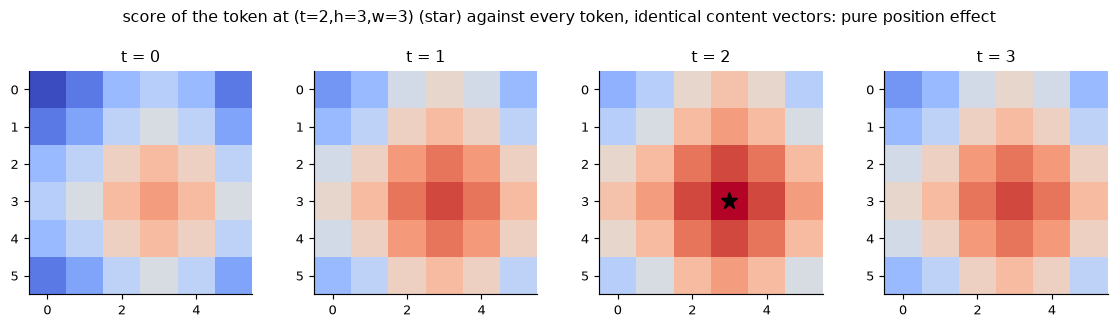

In [4]:
def grid(GT):                                           # (N,3) = (t,h,w) coordinate of every token, row-major
    return torch.stack(torch.meshgrid(torch.arange(GT), torch.arange(GH), torch.arange(GW), indexing="ij"), -1).reshape(-1, 3)
def rope_cache(coords, hd):                             # coords (N,3) -> cos,sin (N, hd/2); head dim split in 3 axis chunks
    d = (hd // 3) // 2 * 2; dims = [d, d, hd - 2 * d]; cs, sn = [], []
    for a, da in enumerate(dims):
        inv = 1.0 / (10000 ** (torch.arange(0, da, 2).float() / da)); ang = coords[:, a:a + 1].float() * inv[None]
        cs.append(ang.cos()); sn.append(ang.sin())
    return torch.cat(cs, 1), torch.cat(sn, 1)
def apply_rope(x, cos, sin):                            # x (B,h,N,hd) ; rotates consecutive pairs (x1,x2)
    x1, x2 = x[..., 0::2], x[..., 1::2]; cos = cos[:, None]; sin = sin[:, None]
    return torch.stack([x1 * cos - x2 * sin, x1 * sin + x2 * cos], -1).flatten(-2)
def rope_bn(coords, hd, B):                             # coords (B,N,3) -> cos,sin (B,N,hd/2)
    c, s = rope_cache(coords.reshape(-1, 3), hd); return c.view(B, -1, c.shape[-1]), s.view(B, -1, s.shape[-1])

# ---- check 1: score depends only on the relative offset (1D intuition, on the time chunk) ----
hd = 24; torch.manual_seed(0); q = torch.randn(1, 1, 1, hd); k = torch.randn(1, 1, 1, hd)
def score(tq, tk, hq=0, hk=0, wq=0, wk=0):
    cq, sq = rope_cache(torch.tensor([[tq, hq, wq]]), hd); ck, sk = rope_cache(torch.tensor([[tk, hk, wk]]), hd)
    return (apply_rope(q, cq[None], sq[None]) * apply_rope(k, ck[None], sk[None])).sum().item()
s1, s2, s3 = score(3, 5), score(10, 12), score(100, 102)
check("RoPE: score(q at t, k at t+2) is the same for t=3, 10, 100 (depends only on offset)", abs(s1 - s2) < 1e-5 and abs(s1 - s3) < 1e-4, f"{s1:.5f} {s2:.5f} {s3:.5f}")
check("RoPE: ...but changes when the offset changes", abs(score(3, 5) - score(3, 6)) > 1e-3)
# ---- check 2: 3D - shifting every token by the same (dt,dh,dw) leaves ALL pairwise scores unchanged ----
N = 4 * GH * GW; Q = torch.randn(1, 1, N, hd); K = torch.randn(1, 1, N, hd); g = grid(4)
def scores(coords):
    c, s = rope_cache(coords, hd); return (apply_rope(Q, c[None], s[None]) @ apply_rope(K, c[None], s[None]).transpose(-1, -2))[0, 0]
S0 = scores(g); S1 = scores(g + torch.tensor([7, 3, 5]))
check("3D-RoPE: translating the whole clip in (t,h,w) leaves attention scores unchanged", torch.allclose(S0, S1, atol=1e-4), f"max diff {(S0 - S1).abs().max():.1e}")
# ---- visual: similarity of a fixed content vector placed at all positions, queried from the centre token ----
qc = torch.ones(1, 1, 1, hd); kk = torch.ones(1, 1, N, hd); centre = int(((2 * GH + 3) * GW + 3))
c, s = rope_cache(g, hd); cq, sq = c[centre:centre + 1], s[centre:centre + 1]
sim = (apply_rope(qc, cq[None], sq[None]) * apply_rope(kk, c[None], s[None])).sum(-1)[0, 0].reshape(4, GH, GW)
fig, axs = plt.subplots(1, 4, figsize=(11, 2.8))
for i in range(4): im = axs[i].imshow(sim[i], cmap="coolwarm", vmin=sim.min(), vmax=sim.max()); axs[i].set_title(f"t = {i}"); axs[i].grid(False)
axs[2].plot(3, 3, "k*", ms=12); plt.suptitle("score of the token at (t=2,h=3,w=3) (star) against every token, identical content vectors: pure position effect", y=1.04); plt.tight_layout(); plt.show()

## Step 4 - What to hide: multi-block masking 🙈

The self-supervised task is **mask denoising in representation space** (paper §2.1): hide part of the video, and from what remains predict the *representation* of what was hidden.

Design question: *what* to hide? If you hide random single patches, a pixel in the next frame is trivially interpolated from its neighbours in space and time. V-JEPA uses **multi-block masks**: the *union of a few large rectangular blocks*, extended across **all frames** ("a large continuous block that covers the full temporal dimension limits information leakage due to the spatial and temporal redundancy of videos", Bardes et al.). The model must truly *infer* what happens inside the hole - including motion.

<p align="center"><img src="images/r_ijepa_fig4.png" width="520"><br><sub>Fig. 4 (I-JEPA) - the image version of the idea: a context block (2nd column) and several target blocks (right) whose representations must be predicted.</sub></p>

Paper hyper-parameters (Table 9): spatial block scale `[0.15, 0.7]`, aspect ratio `[0.75, 1.5]`, **temporal mask scale `[1.0, 1.0]`** (= full time), tubelet 2, patch 16. V-JEPA 1 (Bardes et al.) describes the two mask types: *short-range* = union of **8** blocks each covering ~15 % of the frame, *long-range* = union of **2** blocks covering ~70 %; together an average masking ratio of **~90 %**.

Our toy grid is only 6×6 patches, so we use a gentler `4` blocks × `20 %` (overlaps and the trimming below leave roughly a third of the tokens hidden). One more practical trick (also in the official code): every sample in a batch must have the **same number** of masked tokens so we can batch them - we randomly *un-mask* extra spatial cells (whole columns through time, so the hole stays identical in every frame).

tokens per clip N=144;  visible Nv=96, masked Nm=48  ->  masking ratio 33%
PASS keep and pred are disjoint and cover every token
PASS all samples have the same number of masked tokens (batchable)
PASS holes span the full temporal extent (same spatial positions at every time layer)


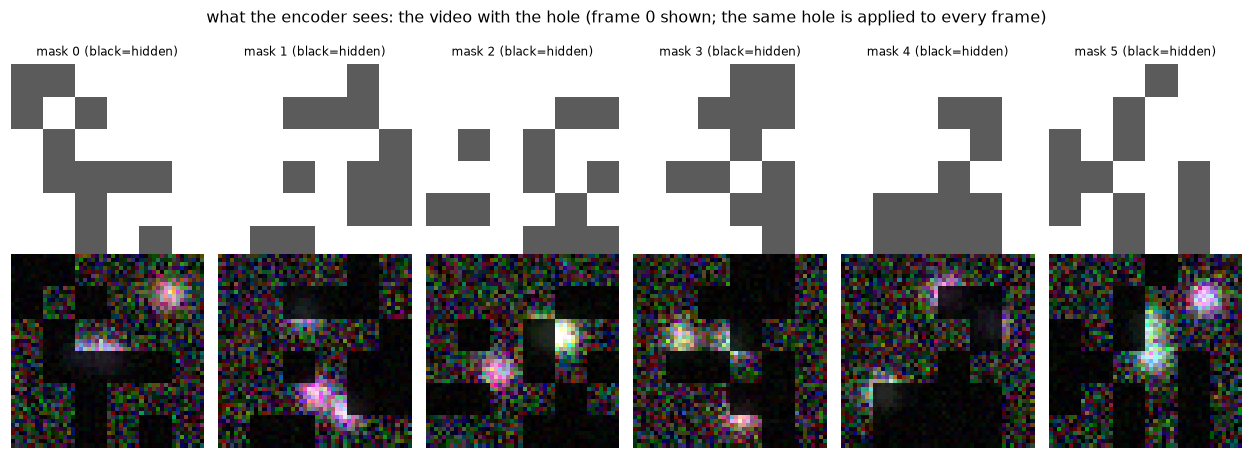

In [5]:
def multiblock_mask(B, GT, nblocks=4, scale=0.2, ar=(0.75, 1.5)):
    """returns keep (B,Nv) and pred (B,Nm) token indices. Blocks are spatial, repeated for every temporal layer."""
    N = GT * GH * GW; m = torch.zeros(B, GH, GW, dtype=torch.bool)
    for b in range(B):
        for _ in range(nblocks):
            area = scale * GH * GW; r = math.exp(math.log(ar[0]) + (math.log(ar[1]) - math.log(ar[0])) * float(torch.rand(1)))
            h = max(1, min(GH, round(math.sqrt(area * r)))); w = max(1, min(GW, round(math.sqrt(area / r))))
            y = int(torch.randint(0, GH - h + 1, (1,))); x = int(torch.randint(0, GW - w + 1, (1,))); m[b, y:y + h, x:x + w] = True
    ms = m.reshape(B, GH * GW); k = int(ms.sum(1).min()); sel = torch.zeros_like(ms)          # equal-size trick, done on SPATIAL cells so the hole stays identical in every time layer
    for b in range(B):
        ci = ms[b].nonzero().squeeze(1); sel[b, ci[torch.randperm(len(ci))[:k]]] = True
    mt = sel[:, None, :].expand(B, GT, GH * GW).reshape(B, N)                                    # full temporal extent
    keep = torch.stack([(~mt[b]).nonzero().squeeze(1) for b in range(B)]); pred = torch.stack([mt[b].nonzero().squeeze(1) for b in range(B)])
    return keep, pred

keep, pred = multiblock_mask(64, 4); N = 4 * GH * GW
ok_disj = all(len(set(keep[b].tolist()) & set(pred[b].tolist())) == 0 for b in range(64))
ok_union = all(len(set(keep[b].tolist()) | set(pred[b].tolist())) == N for b in range(64))
t_of = lambda idx: idx // (GH * GW); s_of = lambda idx: idx % (GH * GW)
ok_time = all(set(s_of(pred[b]).tolist()) == set(s_of(pred[b][t_of(pred[b]) == 0]).tolist()) for b in range(64) if (t_of(pred[b]) == 0).any())
ratio = pred.shape[1] / N
print(f"tokens per clip N={N};  visible Nv={keep.shape[1]}, masked Nm={pred.shape[1]}  ->  masking ratio {ratio:.0%}")
check("keep and pred are disjoint and cover every token", ok_disj and ok_union)
check("all samples have the same number of masked tokens (batchable)", pred.shape[1] == pred[0].numel() and keep.shape == (64, keep.shape[1]))
check("holes span the full temporal extent (same spatial positions at every time layer)", ok_time)

fig, axs = plt.subplots(2, 6, figsize=(12, 4.3))
vv, _, _ = make_video(6)
for i in range(6):
    mk = torch.zeros(N); mk[pred[i]] = 1; mk = mk.reshape(4, GH, GW)
    axs[0, i].imshow(mk[0], cmap="Greys", vmin=0, vmax=1.4); axs[0, i].set_title(f"mask {i} (black=hidden)", fontsize=8); axs[0, i].axis("off")
    f = vv[i, :, 0].permute(1, 2, 0).clamp(0, 1).clone(); up = mk[0].repeat_interleave(PS, 0).repeat_interleave(PS, 1)
    f[up > 0] = f[up > 0] * 0.15; axs[1, i].imshow(f); axs[1, i].axis("off")
plt.suptitle("what the encoder sees: the video with the hole (frame 0 shown; the same hole is applied to every frame)", y=1.0); plt.tight_layout(); plt.show()

## Step 5 - The encoder: a ViT that sees only what is visible 👁️

Both the encoder `E_θ` and the predictor `P_φ` are plain **Vision Transformers**. A block is the standard pre-norm recipe:

`x ← x + Attn(LN(x))` ; `x ← x + MLP(LN(x))` with `MLP = Linear → GELU → Linear` (4× width) and **RoPE applied to q and k** inside attention.

Crucial efficiency trick (as in MAE): the encoder processes **only the visible tokens** (`Nv`), not the whole clip - with ~90 % masking in the paper that is ~10× cheaper per step. The positions of the visible tokens are carried by RoPE, so dropping tokens loses nothing about *where* the survivors are.

<p align="center"><img src="images/r_mae_fig1.png" width="560"><br><sub>Fig. 1 (MAE, He et al. 2021) - the same asymmetry: a big encoder sees only visible patches. (MAE reconstructs pixels with a decoder; V-JEPA regresses encoder features with a predictor.)</sub></p>

In [6]:
class Block(nn.Module):
    def __init__(s, D, h):
        super().__init__(); s.h = h; s.n1 = nn.LayerNorm(D); s.qkv = nn.Linear(D, 3 * D); s.o = nn.Linear(D, D); s.n2 = nn.LayerNorm(D)
        s.mlp = nn.Sequential(nn.Linear(D, 4 * D), nn.GELU(), nn.Linear(4 * D, D))
    def forward(s, x, cos, sin, attn_mask=None):
        B, N, D = x.shape; q, k, v = s.qkv(s.n1(x)).view(B, N, 3, s.h, D // s.h).permute(2, 0, 3, 1, 4)
        q = apply_rope(q, cos, sin); k = apply_rope(k, cos, sin)                          # <- position enters ONLY here
        a = F.scaled_dot_product_attention(q, k, v, attn_mask=attn_mask).transpose(1, 2).reshape(B, N, D)
        x = x + s.o(a); return x + s.mlp(s.n2(x))

class Encoder(nn.Module):
    def __init__(s, D=96, depth=4, h=4):
        super().__init__(); s.D = D; s.h = h; s.embed = nn.Conv3d(3, D, (PT, PS, PS), stride=(PT, PS, PS))
        s.blocks = nn.ModuleList([Block(D, h) for _ in range(depth)]); s.norm = nn.LayerNorm(D)
    def forward(s, vid, keep=None):                       # keep (B,Nv): indices of visible tokens, or None = see everything
        x = s.embed(vid); GT = x.shape[2]; x = x.flatten(2).transpose(1, 2); B = x.shape[0]
        if keep is not None: x = torch.gather(x, 1, keep[..., None].expand(-1, -1, s.D)); pos = grid(GT)[keep]
        else: pos = grid(GT)[None].expand(B, -1, -1)
        cos, sin = rope_bn(pos, s.D // s.h, B)
        for b in s.blocks: x = b(x, cos, sin)
        return s.norm(x)

enc = Encoder(); v, _, _ = make_video(4); keep, pred = multiblock_mask(4, 4)
z_all, z_vis = enc(v), enc(v, keep)
print("encoder on all tokens:", tuple(z_all.shape), "  on visible tokens only:", tuple(z_vis.shape))
check("encoder on visible tokens returns Nv vectors of dim D", z_vis.shape == (4, keep.shape[1], 96))

# ---- parameter counts: our block formula reproduces the paper's Table 12 ----
def vit_params(width, depth, mlp):                          # per block: qkv + proj + 2 LN + 2 MLP linears
    blk = (3 * width * width + 3 * width) + (width * width + width) + 2 * 2 * width + (width * mlp + mlp) + (mlp * width + width)
    return depth * blk + 2 * width
table12 = {"ViT-L": (1024, 24, 4096, 300e6), "ViT-H": (1280, 32, 5120, 600e6), "ViT-g": (1408, 40, 6144, 1e9), "predictor ViT-s": (384, 12, 1536, 22e6)}
print(f"\n{'model':16s} {'width':>6s} {'depth':>5s} {'mlp':>5s} {'ours':>9s} {'paper Table 12':>15s}")
for n_, (w_, d_, m_, ref) in table12.items():
    p_ = vit_params(w_, d_, m_); print(f"{n_:16s} {w_:6d} {d_:5d} {m_:5d} {p_ / 1e6:8.0f}M {ref / 1e6:14.0f}M")
    check(f"{n_}: counted params within 6% of the paper's rounded figure", abs(p_ - ref) / ref < 0.06, f"{p_ / 1e6:.0f}M vs {ref / 1e6:.0f}M")
print("\nOur toy encoder:", f"{sum(p.numel() for p in enc.parameters()) / 1e6:.2f}M params")

encoder on all tokens: (4, 144, 96)   on visible tokens only: (4, 76, 96)
PASS encoder on visible tokens returns Nv vectors of dim D

model             width depth   mlp      ours  paper Table 12
ViT-L              1024    24  4096      302M            300M
PASS ViT-L: counted params within 6% of the paper's rounded figure   [302M vs 300M]
ViT-H              1280    32  5120      630M            600M
PASS ViT-H: counted params within 6% of the paper's rounded figure   [630M vs 600M]
ViT-g              1408    40  6144     1010M           1000M
PASS ViT-g: counted params within 6% of the paper's rounded figure   [1010M vs 1000M]
predictor ViT-s     384    12  1536       21M             22M
PASS predictor ViT-s: counted params within 6% of the paper's rounded figure   [21M vs 22M]

Our toy encoder: 0.48M params


## Step 6 - The predictor: fill the hole with *mask tokens* 🧩

The predictor `P_φ` receives
1. the encoder's outputs for the **visible** tokens (projected to the predictor's width),
2. one **learnable mask token** `Δy` for every **hidden** position - the same vector for all, so it carries *no content*, only a request: "tell me what is here".

Each token gets its RoPE position, so a mask token at `(t=2, h=3, w=1)` *knows where it is* and can attend to visible tokens around it in space and time. The predictor's outputs **at the mask positions** are projected back to the encoder's width and compared with targets. (Paper Fig. 2 left: "the outputs of the encoder are concatenated with a set of learnable mask tokens that specify the position of the masked patches".)

The predictor is much smaller than the encoder: **ViT-s (22 M)** next to a 300 M-1 B encoder (Table 12) - it only has to *route* information, the heavy lifting of "what is in this patch" is in the encoder.

<p align="center"><img src="images/p_fig2_training.png" width="820"><br><sub>Fig. 2 (paper), left half - V-JEPA 2 pre-training: encoder sees masked video; predictor gets encoder outputs + mask tokens z; target comes from an EMA copy of the encoder with stop-gradient; L1 loss. Right half (V-JEPA 2-AC) is Step 10.</sub></p>

In [7]:
class Predictor(nn.Module):
    def __init__(s, D=96, Dp=64, depth=2, h=4):
        super().__init__(); s.h = h; s.inp = nn.Linear(D, Dp); s.mask_tok = nn.Parameter(torch.randn(1, 1, Dp) * 0.02)   # the learnable Δy
        s.blocks = nn.ModuleList([Block(Dp, h) for _ in range(depth)]); s.norm = nn.LayerNorm(Dp); s.out = nn.Linear(Dp, D)
    def forward(s, z, keep, pidx, GT):                    # z (B,Nv,D) encoder outputs of visible tokens
        B, Nv, _ = z.shape; Nm = pidx.shape[1]
        x = torch.cat([s.inp(z), s.mask_tok.expand(B, Nm, -1)], 1)          # [visible tokens | mask tokens]
        idx = torch.cat([keep, pidx], 1); cos, sin = rope_bn(grid(GT)[idx], x.shape[-1] // s.h, B)   # each token keeps ITS OWN position
        for b in s.blocks: x = b(x, cos, sin)
        return s.out(s.norm(x[:, Nv:]))                                      # predictions only at mask positions

pr = Predictor(); zhat = pr(z_vis, keep, pred, 4)
print("visible", tuple(z_vis.shape), "+", pred.shape[1], "mask tokens ->", tuple(zhat.shape), "(one prediction per hidden token)")
check("predictor outputs exactly one D-vector per masked token", zhat.shape == (4, pred.shape[1], 96))
# the mask tokens are content-free: two hidden positions differ ONLY through their RoPE position -> outputs differ because of context, not identity
check("predictor is much smaller than the encoder (as in the paper, 22M vs 300M-1B)", sum(p.numel() for p in pr.parameters()) < sum(p.numel() for p in enc.parameters()))

visible (4, 76, 96) + 68 mask tokens -> (4, 68, 96) (one prediction per hidden token)
PASS predictor outputs exactly one D-vector per masked token
PASS predictor is much smaller than the encoder (as in the paper, 22M vs 300M-1B)


## Step 7 - The target, the loss, and the collapse problem ⚖️

**Equation (1) of the paper:**

`minimize_{θ, φ, Δy}  ‖ P_φ(Δy, E_θ(x)) − sg( E_θ̄(y) ) ‖₁`

- `x` = the masked view, `y` = the full video; the loss is applied **only to the masked positions**.
- `sg(·)` = **stop-gradient**: the target is a constant for the optimiser.
- `θ̄` = an **exponential moving average** of the encoder weights: `θ̄ ← m·θ̄ + (1−m)·θ` (paper: `m = 0.99925`, fixed).
- **L1** rather than L2 (robust to outlier features; V-JEPA 1 noted it was more stable).
- *Not in the paper text but in the official code* (`app/vjepa/train.py`): the target features are passed through `F.layer_norm` (no affine) before the loss. We do the same.

**Why EMA + stop-grad? Collapse.** If target and prediction came from the *same network with gradients on both sides*, the trivial solution is `E(x) = constant`: the predictor then predicts the constant perfectly, loss = 0, and the encoder has learned nothing. The EMA teacher moves slowly and receives no gradient, so it cannot be dragged to a constant by the student; the student must chase a target that is a *lagged copy of itself*. (BYOL, Grill et al. 2020, found the same recipe; its architecture figure is below.)

<p align="center"><img src="images/r_byol_fig2.png" width="700"><br><sub>Fig. 2 (BYOL) - online network predicts the target network's projection; target = EMA of online weights, sg = stop-gradient. V-JEPA 2's Fig. 2 has the same shape.</sub></p>

In [8]:
def jepa_loss(z_pred, h_target, pidx, stop_grad=True):
    """Eq. (1): L1 between predictor output and layer-normed target features, masked positions only. sg(.) = detach."""
    h = F.layer_norm(h_target, (h_target.shape[-1],)); h = torch.gather(h, 1, pidx[..., None].expand(-1, -1, h.shape[-1]))
    return (z_pred - (h.detach() if stop_grad else h)).abs().mean()

@torch.no_grad()
def ema_update(student, teacher, m):
    for ps_, pt_ in zip(student.parameters(), teacher.parameters()): pt_.mul_(m).add_(ps_, alpha=1 - m)

# ---- check the EMA update against its closed form: theta_bar_n = m^n * theta_bar_0 + (1-m) * sum_k m^(n-1-k) * theta_k ----
torch.manual_seed(0); st = nn.Linear(3, 1); te = copy.deepcopy(st); m = 0.9; w0 = te.weight.clone(); hist = []
for n in range(6):
    with torch.no_grad(): st.weight.add_(torch.randn_like(st.weight))
    hist.append(st.weight.clone()); ema_update(st, te, m)
closed = m ** 6 * w0 + (1 - m) * sum(m ** (5 - k) * hist[k] for k in range(6))
check("EMA update equals its closed-form weighted sum of past student weights", torch.allclose(te.weight, closed, atol=1e-6))
print(f"paper's m = 0.99925 -> the teacher averages over roughly 1/(1-m) = {1 / (1 - 0.99925):.0f} steps (of 252K total iterations)")
check("stop-gradient: the target branch receives no gradient", all(p.grad is None for p in te.parameters()))

PASS EMA update equals its closed-form weighted sum of past student weights
paper's m = 0.99925 -> the teacher averages over roughly 1/(1-m) = 1333 steps (of 252K total iterations)
PASS stop-gradient: the target branch receives no gradient


## Step 8 - Train a tiny V-JEPA, then *freeze* it and test what it learned 🧪

**Setup.** Encoder: 4 blocks, width 96 (0.48 M params). Predictor: 2 blocks, width 64. AdamW, cosine LR, EMA `m = 0.99` (the paper's 0.99925 is tuned for 252 K steps; with ~2 K steps it would barely move). A small fraction of batches (15 %) are **static "image" clips** (`T=2`, no motion), mirroring the paper's trick of treating images as repeated-frame clips so one model covers both - we will need this in Step 10 because V-JEPA 2-AC encodes single frames.

**Three arms.** (A) the real recipe: EMA teacher + stop-grad. (B) control *stop-grad only*: target = the current encoder, detached, no EMA. (C) control *neither*: target = the same encoder with gradients flowing through it. We track **feature spread** (`feat-std`: the standard deviation across tokens of the layer-normed features; ≈0 means all tokens look the same = **collapse**).

**Evaluation = the paper's protocol, miniaturised.** Freeze the encoder and train a small probe on its features to read out the blob's **direction of motion** (8 classes). Direction needs *several frames*, like Something-Something v2 in the paper ("motion understanding"). Baseline: a **randomly initialised** encoder with the same probe. Two probes: an *attentive probe* (learnable query cross-attending to tokens, as in the paper's 4-layer probe but 1 layer here) and a stricter *mean-pool + linear* probe.

In [9]:
def feat_std(enc, vid):
    with torch.no_grad(): h = F.layer_norm(enc(vid), (enc.D,))
    return h.reshape(-1, enc.D).std(0).mean().item()

def cosine_lr(it, total, base, warm=100, final=1e-5):
    if it < warm: return base * (it + 1) / warm
    return final + (base - final) * 0.5 * (1 + math.cos(math.pi * (it - warm) / max(1, total - warm)))

def pretrain(steps, seed=0, mode="ema", lr=1e-3, m_ema=0.99, B=32, log=200, p_image=0.15, v_eval=None):
    torch.manual_seed(seed); enc = Encoder(); pred = Predictor(); tgt = copy.deepcopy(enc).requires_grad_(False)
    opt = torch.optim.AdamW(list(enc.parameters()) + list(pred.parameters()), lr=lr, weight_decay=0.04); loss_hist, std_hist = [], []; t0 = time.time()
    for it in range(steps):
        for g_ in opt.param_groups: g_["lr"] = cosine_lr(it, steps, lr)
        img = float(torch.rand(1)) < p_image; T = 2 if img else 8; GT = T // PT
        vid, _, _ = make_video(B, T=T, static=img); keep, pidx = multiblock_mask(B, GT)
        if mode == "ema":                                                # (A) the real recipe: EMA teacher + stop-grad
            with torch.no_grad(): h = tgt(vid)
        else: h = enc(vid)                                               # controls: the target is the STUDENT itself
        loss = jepa_loss(pred(enc(vid, keep), keep, pidx, GT), h, pidx, stop_grad=(mode != "no_sg"))   # (B) "sg_only": stop-grad, no EMA   (C) "no_sg": gradients through target too
        opt.zero_grad(); loss.backward(); opt.step()
        if mode == "ema": ema_update(enc, tgt, m_ema)
        loss_hist.append(loss.item())
        if it % 50 == 0 and v_eval is not None: std_hist.append((it, feat_std(enc, v_eval)))
        if log and it % log == 0: print(f"[{mode}] step {it:5d}  L1 {loss.item():.4f}  feat-std {std_hist[-1][1] if std_hist else float('nan'):.3f}  {time.time() - t0:.0f}s", flush=True)
    return enc, pred, tgt, loss_hist, std_hist

In [10]:
class AttnProbe(nn.Module):                                   # learnable query cross-attends to frozen tokens (the paper's probe ends in such a layer)
    def __init__(s, D, ncls=8):
        super().__init__(); s.q = nn.Parameter(torch.randn(1, 1, D) * 0.02); s.ln = nn.LayerNorm(D); s.att = nn.MultiheadAttention(D, 4, batch_first=True); s.fc = nn.Linear(D, ncls)
    def forward(s, z): z = s.ln(z); o, _ = s.att(s.q.expand(z.shape[0], -1, -1), z, z); return s.fc(o[:, 0])
class MeanProbe(nn.Module):                                   # stricter: average all tokens, then one linear layer
    def __init__(s, D, ncls=8): super().__init__(); s.ln = nn.LayerNorm(D); s.fc = nn.Linear(D, ncls)
    def forward(s, z): return s.fc(s.ln(z).mean(1))
def probe_acc(enc, kind="attn", ntr=1000, nte=600, steps=400, seed=1):
    torch.manual_seed(seed); vtr, ytr, _ = make_video(ntr); vte, yte, _ = make_video(nte)
    with torch.no_grad():
        ftr = torch.cat([enc(vtr[i:i + 250]) for i in range(0, ntr, 250)]); fte = torch.cat([enc(vte[i:i + 250]) for i in range(0, nte, 250)])   # ENCODER IS FROZEN: features computed once
    p = (AttnProbe if kind == "attn" else MeanProbe)(enc.D); opt = torch.optim.AdamW(p.parameters(), 2e-3, weight_decay=0.01)
    for s in range(steps):
        i = torch.randint(0, ntr, (128,)); l = F.cross_entropy(p(ftr[i]), ytr[i]); opt.zero_grad(); l.backward(); opt.step()
    with torch.no_grad(): return (p(fte).argmax(1) == yte).float().mean().item()

In [11]:
STEPS_MAIN, STEPS_CTRL, AC_STEPS = 2000, 500, 1200          # toy budgets (CPU). Paper: 252,000 iterations at batch 3072.
v_eval, _, _ = make_video(64)
t0 = time.time()
enc_ns, _, _, loss_ns, std_ns = pretrain(STEPS_CTRL, mode="no_sg", v_eval=v_eval, log=250)           # control C: no EMA, no stop-grad
enc_sg, _, _, loss_sg, std_sg = pretrain(STEPS_CTRL, mode="sg_only", v_eval=v_eval, log=250)         # control B: stop-grad, no EMA
enc_j, pred_j, tgt_j, loss_j, std_j = pretrain(STEPS_MAIN, mode="ema", v_eval=v_eval, log=250)       # arm A: the real recipe
print(f"total pre-training wall time {time.time() - t0:.0f}s")

[no_sg] step     0  L1 0.9695  feat-std 0.241  1s


[no_sg] step   250  L1 0.0159  feat-std 0.013  181s


[sg_only] step     0  L1 0.9695  feat-std 0.242  1s


[sg_only] step   250  L1 0.0440  feat-std 0.055  98s


[ema] step     0  L1 0.9695  feat-std 0.242  1s


[ema] step   250  L1 0.0592  feat-std 0.068  157s


... (3 outputs left out)

[ema] step  1250  L1 0.2592  feat-std 0.757  778s


[ema] step  1500  L1 0.2808  feat-std 0.782  833s


[ema] step  1750  L1 0.2535  feat-std 0.776  863s


total pre-training wall time 1486s


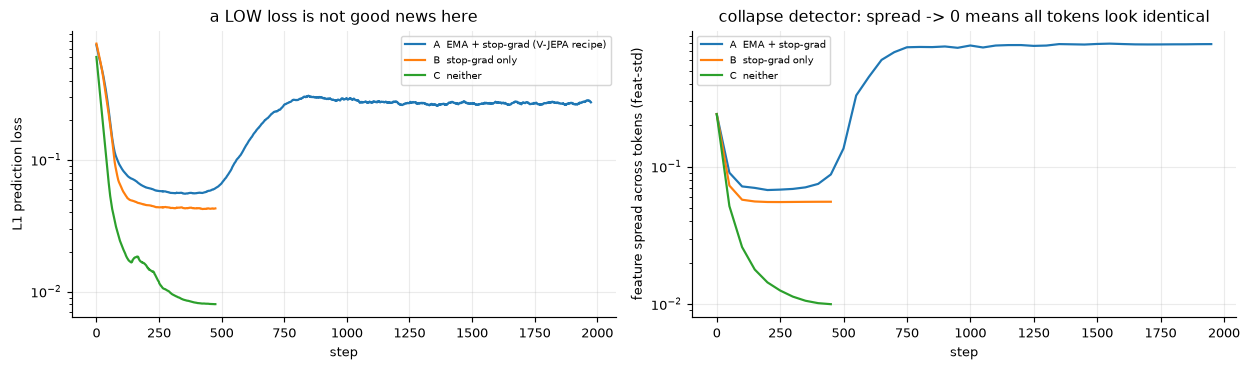

final feat-std:  A (EMA+sg) 0.780 | B (sg only) 0.056 | C (neither) 0.010   (random-init encoder: 0.257)
final L1 loss:   A 0.2744 | B 0.0428 | C 0.0080
PASS control C (no EMA, no stop-grad) collapses: feature spread falls below 0.02   [0.0100]
PASS the V-JEPA recipe (A) keeps a healthy feature spread (> 0.1) at the end   [0.780]
PASS collapsed run reaches a LOWER loss than the healthy run (loss alone cannot tell you the model works)


In [12]:
fig, axs = plt.subplots(1, 2, figsize=(12, 3.6)); k = 25; sm = lambda x: np.convolve(x, np.ones(k) / k, mode="valid")
axs[0].plot(sm(loss_j), label="A  EMA + stop-grad (V-JEPA recipe)"); axs[0].plot(sm(loss_sg), label="B  stop-grad only"); axs[0].plot(sm(loss_ns), label="C  neither"); axs[0].set_yscale("log"); axs[0].set_xlabel("step"); axs[0].set_ylabel("L1 prediction loss"); axs[0].legend(fontsize=7); axs[0].set_title("a LOW loss is not good news here")
for std, lab in [(std_j, "A  EMA + stop-grad"), (std_sg, "B  stop-grad only"), (std_ns, "C  neither")]: axs[1].plot(*zip(*std), label=lab)
axs[1].set_yscale("log"); axs[1].set_xlabel("step"); axs[1].set_ylabel("feature spread across tokens (feat-std)"); axs[1].legend(fontsize=7); axs[1].set_title("collapse detector: spread -> 0 means all tokens look identical")
plt.tight_layout(); plt.show()
fin = lambda s: s[-1][1]
print(f"final feat-std:  A (EMA+sg) {fin(std_j):.3f} | B (sg only) {fin(std_sg):.3f} | C (neither) {fin(std_ns):.3f}   (random-init encoder: {feat_std(Encoder(), v_eval):.3f})")
print(f"final L1 loss:   A {np.mean(loss_j[-50:]):.4f} | B {np.mean(loss_sg[-50:]):.4f} | C {np.mean(loss_ns[-50:]):.4f}")
check("control C (no EMA, no stop-grad) collapses: feature spread falls below 0.02", fin(std_ns) < 0.02, f"{fin(std_ns):.4f}")
check("the V-JEPA recipe (A) keeps a healthy feature spread (> 0.1) at the end", fin(std_j) > 0.1, f"{fin(std_j):.3f}")
check("collapsed run reaches a LOWER loss than the healthy run (loss alone cannot tell you the model works)", np.mean(loss_ns[-50:]) < np.mean(loss_j[-50:]))

In [13]:
torch.manual_seed(0); enc_rand = Encoder()                         # random-init baseline, same architecture
tab = {}
for name, e in [("random init", enc_rand), ("C: neither", enc_ns), ("B: stop-grad only", enc_sg), ("A: V-JEPA (EMA+sg)", enc_j)]:
    e.eval(); tab[name] = (feat_std(e, v_eval), probe_acc(e, "attn"), probe_acc(e, "mean"))
print(f"{'frozen encoder':22s} {'feat-std':>9s} {'attentive probe':>16s} {'mean-pool linear':>17s}    (chance = 12.5 %; direction of motion, 8 classes, 600 test clips)")
for n_, (fs_, a_, m_) in tab.items(): print(f"{n_:22s} {fs_:9.3f} {100 * a_:15.1f}% {100 * m_:16.1f}%")
print("\nNOTE: read these numbers before the next paragraph - they do not show the trained encoder winning on this probe.")

frozen encoder          feat-std  attentive probe  mean-pool linear    (chance = 12.5 %; direction of motion, 8 classes, 600 test clips)
random init                0.241            62.5%             12.5%
C: neither                 0.010            14.7%             10.8%
B: stop-grad only          0.056            41.0%             10.8%
A: V-JEPA (EMA+sg)         0.776            16.0%             16.3%

NOTE: read these numbers before the next paragraph - they do not show the trained encoder winning on this probe.


In [14]:
# What did the encoder actually learn?  Decompose feature variance (law of total variance): how much of it is explained by WHICH TOKEN POSITION it is, regardless of the clip?
def position_share(e, n=256):
    torch.manual_seed(9); v, _, _ = make_video(n)
    with torch.no_grad(): f = F.layer_norm(e(v), (e.D,))                                   # (clips, tokens, D)
    return (f.mean(0).var(0) / f.reshape(-1, e.D).var(0)).mean().item()                    # variance of per-position means / total variance, averaged over feature dims
ps = {nm: position_share(e) for nm, e in [("random init", enc_rand), ("C: neither", enc_ns), ("B: stop-grad only", enc_sg), ("A: V-JEPA (EMA+sg)", enc_j)]}
for nm, v_ in ps.items(): print(f"{nm:22s} share of feature variance explained by token position alone: {100 * v_:5.1f}%")

random init            share of feature variance explained by token position alone:   4.3%
C: neither             share of feature variance explained by token position alone:   0.5%
B: stop-grad only      share of feature variance explained by token position alone:   9.6%
A: V-JEPA (EMA+sg)     share of feature variance explained by token position alone:  29.4%


### What did the frozen encoder actually learn?

**A negative result first.** On the direction-of-motion probe the trained V-JEPA encoder does **not** beat a randomly initialised one in our toy: the attentive probe reads 16 % from the trained encoder against 62.5 % from the random one (chance 12.5 %), and the mean-pool probe is near chance for both (16 % vs 12.5 %). We expected the opposite. Two measurements below say what the encoder did learn instead. Only the controls' collapse numbers (Step 7-8 above) and the planning results (Steps 10-11) are the clean, robust effects in this notebook; this probe is not, and we ran a single seed.

**Where position fits.** The PCA maps show a similar smooth spatial pattern in every clip. We measured how much of the feature variance is explained by token position alone (printed above): 29 % for the trained encoder against 4 % for the random one. That is a large increase, so positional structure is a real part of the learned features, but it is a minority of the variance, so we do not claim position is the whole story.

**Noise versus motion.** For the same scene we make two input perturbations and compare how far the representation moves: a fresh draw of pixel noise (nothing meaningful changed) and a reversal of the blob's direction (the meaningful change). `sensitivity ratio = change from motion / change from noise`; a representation that discards noise and keeps motion scores high. This one does move in the expected direction (below), but note that it measures *sensitivity* to motion, not that the direction can be *decoded*, which is what the probe above tests.


In [15]:
torch.manual_seed(5); Bn = 64; ang0 = torch.randint(0, 8, (Bn,)); spd = torch.empty(Bn).uniform_(1.8, 2.5)
def clip2(ang, noise_seed):
    torch.manual_seed(77); v1 = make_video(Bn, ang=ang, speed=spd, noise=0.0)[0]                       # scene + trajectory, no noise
    torch.manual_seed(noise_seed); nz = 0.15 * torch.randn_like(v1); return v1 + nz
x_a = clip2(ang0, 1); x_b = clip2(ang0, 2); x_c = clip2((ang0 + 4) % 8, 1)                             # b: new noise ; c: opposite direction, SAME noise as a
def feats(e, x):
    with torch.no_grad(): return F.layer_norm(e(x), (e.D,)).flatten(1)
def pix(x): return F.layer_norm(F.avg_pool3d(x, (PT, PS, PS)).flatten(2).transpose(1, 2), (3,)).flatten(1)   # token-level raw pixels (tubelet mean colour)
def ratio(f):
    dn = (f(x_a) - f(x_b)).norm(dim=1).mean(); dm = (f(x_a) - f(x_c)).norm(dim=1).mean(); return (dm / dn).item(), dn.item(), dm.item()
R_pix = ratio(pix); R_rand = ratio(lambda x: feats(enc_rand, x)); R_jepa = ratio(lambda x: feats(enc_j, x))
print(f"{'representation':26s} {'change from noise':>18s} {'change from motion':>19s} {'motion/noise':>13s}")
for n_, r_ in [("raw pixels (tubelet mean)", R_pix), ("random-init encoder", R_rand), ("trained V-JEPA encoder", R_jepa)]: print(f"{n_:26s} {r_[1]:18.2f} {r_[2]:19.2f} {r_[0]:13.2f}")
check("the trained V-JEPA encoder is more motion-vs-noise selective than a random encoder", R_jepa[0] > R_rand[0], f"{R_jepa[0]:.2f} vs {R_rand[0]:.2f}")
check("...and than raw pixels", R_jepa[0] > R_pix[0], f"{R_jepa[0]:.2f} vs {R_pix[0]:.2f}")

representation              change from noise  change from motion  motion/noise
raw pixels (tubelet mean)               21.10                5.99          0.28
random-init encoder                     28.98               10.96          0.38
trained V-JEPA encoder                  25.10               50.53          2.01
PASS the trained V-JEPA encoder is more motion-vs-noise selective than a random encoder   [2.01 vs 0.38]
PASS ...and than raw pixels   [2.01 vs 0.28]


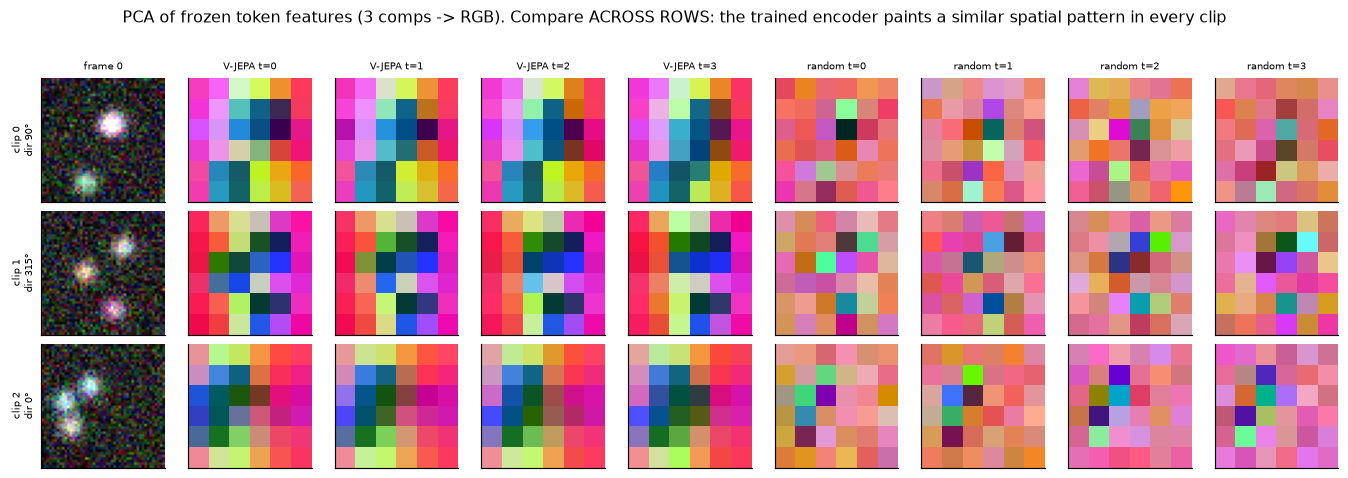

In [16]:
# what does the encoder "see"? PCA of the frozen token features -> RGB (cf. the V-JEPA 2.1 teaser above)
def pca_rgb(e, vid):
    with torch.no_grad(): f = e(vid)[0]                                                              # (N,D)
    f = f - f.mean(0); U, S, V = torch.pca_lowrank(f, q=3); p = (f @ V[:, :3]); p = (p - p.min(0).values) / (p.max(0).values - p.min(0).values + 1e-6)
    return p.reshape(vid.shape[2] // PT, GH, GW, 3)
torch.manual_seed(31); vv, aa, pp = make_video(3)
fig, axs = plt.subplots(3, 9, figsize=(13, 4.4))
for r in range(3):
    pr_ = pca_rgb(enc_j, vv[r:r + 1])
    axs[r, 0].imshow(vv[r, :, 0].permute(1, 2, 0).clamp(0, 1)); axs[r, 0].set_ylabel(f"clip {r}\ndir {int(aa[r]) * 45}°", fontsize=7)
    for t in range(4): axs[r, 1 + t].imshow(pr_[t]); axs[r, 5 + t].imshow(pca_rgb(enc_rand, vv[r:r + 1])[t])
    for c in range(9): axs[r, c].set_xticks([]); axs[r, c].set_yticks([]); axs[r, c].grid(False)
for c, t in enumerate(["frame 0"] + [f"V-JEPA t={t}" for t in range(4)] + [f"random t={t}" for t in range(4)]): axs[0, c].set_title(t, fontsize=7)
plt.suptitle("PCA of frozen token features (3 comps -> RGB). Compare ACROSS ROWS: the trained encoder paints a similar spatial pattern in every clip", y=1.02); plt.tight_layout(); plt.show()

## Step 9 - What makes it *scale*: the V-JEPA 2 recipe 📈

The objective (Steps 4-7) is the same as V-JEPA 1. The paper's contribution in pre-training is a set of **four scaling ingredients** (§2.1-2.4), each measured on the average of 6 frozen-probe tasks (SSv2, Diving-48, Jester, Kinetics, COIN, ImageNet) with a ViT-L baseline:

| ingredient | change | avg. accuracy (paper Fig. 3) |
|---|---|---|
| baseline V-JEPA 1 | ViT-L/16, 2 M videos, 90 K iters, 16 frames @ 256 | 84.2 |
| + **data** | 2 M → **22 M** videos (VideoMix22M) | 85.2 |
| + **model** | 300 M → **1 B** (ViT-L → ViT-g) | 86.7 |
| + **long training** | 90 K → **252 K** iterations | 87.5 |
| + **resolution/length** | 256 → 384 px and 16 → **64 frames** | 88.2 |

<p align="center"><img src="images/p_fig3_scaling.png" width="430"><br><sub>Fig. 3 (paper) - each ingredient helps; total +4.0 points.</sub></p>

Two *engineering* ideas make the last two affordable:

1. **Warmup-constant-cooldown LR** instead of cosine. Train at a constant LR as long as you like; when you want a final model, branch off a *short cooldown*. Many cooldowns can start from checkpoints of one long run.
2. **Progressive resolution.** Do 95 % of training on cheap clips (16 frames, 256 px) and only raise frames/resolution *during the final 12 K-step cooldown*. The paper estimates training ViT-g at 64×384×384 throughout would need ~60 GPU-years.

Hyper-parameters straight from **Table 9**: warmup 12 000 steps `1e-4 → 5.25e-4`; constant `5.25e-4`; cooldown 12 000 steps `5.25e-4 → 1e-6`; weight decay 0.04; EMA 0.99925; global batch 3072.

PASS LR schedule hits Table 9's values: 1e-4 at start, 5.25e-4 at 12K and 240K, 1e-6 at 252K
clip            tokens  cost vs 16f/256px
16f x 256px       2048               1.0x
64f x 256px       8192               6.2x
64f x 384px      18432              22.4x

relative FLOPs for 252K iterations:  all at 64f/384px = 11.1x  the cost of progressive (cheap for 240K + 12K at 64f/384px)
PASS progressive resolution is >10x cheaper than training everything at 64 frames x 384 px (FLOP estimate)   [11.1x]


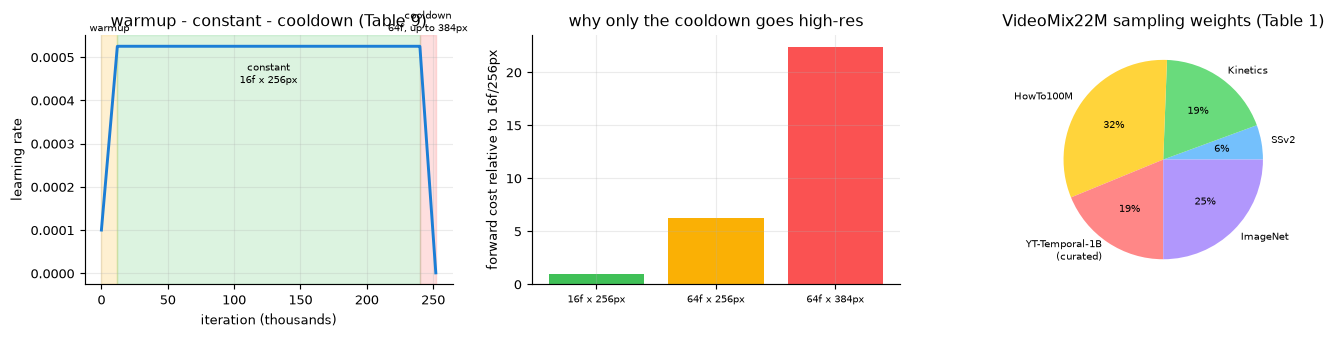

PASS Table 1 sampling weights sum to 1
PASS Fig. 3 increments add up to the +4.0 headline


In [17]:
# ---- the schedule (Table 9) ----
WARM, COOL, TOTAL = 12_000, 12_000, 252_000
def lr_at(s):
    if s < WARM: return 1e-4 + (5.25e-4 - 1e-4) * s / WARM
    if s < TOTAL - COOL: return 5.25e-4
    return 5.25e-4 + (1e-6 - 5.25e-4) * (s - (TOTAL - COOL)) / COOL
check("LR schedule hits Table 9's values: 1e-4 at start, 5.25e-4 at 12K and 240K, 1e-6 at 252K", abs(lr_at(0) - 1e-4) < 1e-12 and abs(lr_at(12_000) - 5.25e-4) < 1e-12 and abs(lr_at(240_000) - 5.25e-4) < 1e-12 and abs(lr_at(252_000) - 1e-6) < 1e-12)

# ---- cost of resolution: forward FLOPs of a ViT-g block stack per clip (all tokens, no masking: relative comparison only) ----
def vit_flops(Ntok, D=1408, L=40, mlp=6144):
    per_layer = 2 * Ntok * (4 * D * D + 2 * D * mlp) + 2 * 2 * Ntok * Ntok * D     # linear layers + attention (QK^T and AV)
    return L * per_layer
cfg = {"16f x 256px": (16, 256), "64f x 256px": (64, 256), "64f x 384px": (64, 384)}
base = vit_flops(n_tokens(16, 256, 256))
print(f"{'clip':14s} {'tokens':>7s} {'cost vs 16f/256px':>18s}")
for n_, (T_, r_) in cfg.items(): print(f"{n_:14s} {n_tokens(T_, r_, r_):7d} {vit_flops(n_tokens(T_, r_, r_)) / base:17.1f}x")
c_cheap = vit_flops(n_tokens(16, 256, 256)); c_hi = vit_flops(n_tokens(64, 384, 384))
prog = (TOTAL - COOL) * c_cheap + COOL * c_hi; flat = TOTAL * c_hi
print(f"\nrelative FLOPs for 252K iterations:  all at 64f/384px = {flat / prog:.1f}x  the cost of progressive (cheap for 240K + 12K at 64f/384px)")
check("progressive resolution is >10x cheaper than training everything at 64 frames x 384 px (FLOP estimate)", flat / prog > 10, f"{flat / prog:.1f}x")

fig, axs = plt.subplots(1, 3, figsize=(13, 3.3))
s = np.linspace(0, TOTAL, 2000); axs[0].plot(s / 1e3, [lr_at(x) for x in s], color="#1c7ed6", lw=2)
for a_, b_, c_, lab in [(0, WARM, "#fab005", "warmup"), (WARM, TOTAL - COOL, "#40c057", "constant\n16f x 256px"), (TOTAL - COOL, TOTAL, "#fa5252", "cooldown\n64f, up to 384px")]:
    axs[0].axvspan(a_ / 1e3, b_ / 1e3, color=c_, alpha=.18); axs[0].text((a_ + b_) / 2e3, 5.6e-4 if "const" not in lab else 4.4e-4, lab, ha="center", fontsize=7)
axs[0].set_xlabel("iteration (thousands)"); axs[0].set_ylabel("learning rate"); axs[0].set_title("warmup - constant - cooldown (Table 9)")
names = list(cfg); axs[1].bar(names, [vit_flops(n_tokens(cfg[n_][0], cfg[n_][1], cfg[n_][1])) / base for n_ in names], color=["#40c057", "#fab005", "#fa5252"]); axs[1].set_ylabel("forward cost relative to 16f/256px"); axs[1].set_title("why only the cooldown goes high-res"); axs[1].tick_params(axis="x", labelsize=7)
src = ["SSv2", "Kinetics", "HowTo100M", "YT-Temporal-1B\n(curated)", "ImageNet"]; wts = [0.056, 0.188, 0.318, 0.188, 0.250]
axs[2].pie(wts, labels=src, autopct="%1.0f%%", textprops={"fontsize": 7}, colors=["#74c0fc", "#69db7c", "#ffd43b", "#ff8787", "#b197fc"]); axs[2].set_title("VideoMix22M sampling weights (Table 1)")
plt.tight_layout(); plt.show()
check("Table 1 sampling weights sum to 1", abs(sum(wts) - 1) < 1e-9)
check("Fig. 3 increments add up to the +4.0 headline", abs((88.2 - 84.2) - 4.0) < 1e-9 and abs(sum([85.2 - 84.2, 86.7 - 85.2, 87.5 - 86.7, 88.2 - 87.5]) - 4.0) < 1e-9)

**Data curation (paper §2.3).** The 1.4 M-hour YT-Temporal-1B is noisy, so they cluster scene embeddings (DINOv2) and *retrieve* scenes close to the target datasets (Kinetics, SSv2, COIN, Epic-Kitchens): **+1.4 points** over uncurated YT1B at ViT-L. **Images** (ImageNet) are added by repeating the image into a 16-frame static clip - exactly the `p_image` trick in our toy pre-training.

Now we have a strong *action-free* video encoder. Steps 10-11 turn it into something a robot can **plan** with.

## Step 10 - V-JEPA 2-AC: bolting actions onto a frozen world model 🤖

V-JEPA 2 can "fill in" missing parts of a video but doesn't know **what an agent's action does**. Stage 2 (paper §3) learns exactly that, from only **~62 hours** of Droid robot video (23 k trajectories, success *and* failure, no rewards, no task labels):

- **Freeze** the V-JEPA 2 encoder `E`. Encode each frame independently: `z_k = E(x_k)` - for ViT-g a `16 × 16 × 1408` feature map.
- Train a **new predictor** `P_φ` (~300 M params: 24 layers, 16 heads, width 1024, GELU) that, given the history of *(action, end-effector state, frame features)*, predicts the **next frame's features** `ẑ_{k+1}`.
- Tokens are **interleaved** per time step: `[a_k, s_k, patches of z_k]` and the attention is **block-causal** - a token at time `k` can attend to everything at times `≤ k`, never the future.
- Action `a_k` = the *change* in 7-D end-effector state (3 position, 3 Euler angles, 1 gripper) between frames k and k+1; state `s_k` = the 7-D end-effector pose itself. 4-second clips at 4 fps = 16 frames.
- RoPE: patches get full 3D-RoPE; **action and state tokens only get the temporal rotation**.

<p align="center"><img src="images/p_fig6_ac_training.png" width="880"><br><sub>Fig. 6 (paper) - left: teacher-forcing loss (predict every next frame from the *true* history). Right: rollout loss (feed the predictor's own output back in, to reduce error accumulation).</sub></p>

**Losses (Eqs. 2-4).**

`L_teacher-forcing(φ) = (1/T) Σ_{k=1..T} ‖ P_φ((a_t, s_t, E(x_t))_{t≤k}) − E(x_{k+1}) ‖₁`, `T = 15`

`L_rollout(φ) = ‖ P_φ(a_{1:T}, s_1, z_1) − z_{T+1} ‖₁`, `T = 2` (gradient only through one recurrent step)

`L(φ) = L_teacher-forcing + L_rollout`

**Our toy version.** The "robot" is the *same blob*, now moved by an action `a = (dx, dy)` (L1-norm ≤ 5 px) instead of by a hidden constant velocity; the state is its `(x, y)` position; the scene has the same noisy background and two static distractors. The encoder is the **frozen toy V-JEPA from Step 8**, applied to a *single* frame duplicated into a 2-frame clip - precisely why we mixed static clips into pre-training. Everything else (interleaving, block-causal attention, temporal-only RoPE for the action/state tokens, both losses) follows the paper.

In [18]:
NP = GH * GW; R_ACT = 5.0                                   # 36 patch tokens per frame ; max action size in px (L1 ball)
class Scene:
    """one fixed scene per episode: textured background + 2 static distractors + a coloured 'gripper' blob that actions move."""
    def __init__(s, B, n_dist=2):
        s.B = B; s.bg = .25 * torch.rand(B, 3, 1, H, W); s.col = torch.rand(B, 3) * .5 + .5; s.dist = 0
        for _ in range(n_dist):
            dp = torch.empty(B, 1, 2).uniform_(8, 40); dc = torch.rand(B, 3) * .5 + .5; s.dist = s.dist + gauss(dp)[:, None] * dc[:, :, None, None, None]
    def render(s, pos, noise=0.15):                         # a single frame, duplicated into a 2-frame clip (an "image" for the encoder)
        f = s.bg + noise * torch.randn(s.B, 3, 1, H, W) + s.dist + gauss(pos[:, None])[:, None] * s.col[:, :, None, None, None]
        return f.expand(-1, -1, PT, -1, -1).contiguous()
def proj_l1(a, r=1.0): return a * torch.clamp(r / (a.abs().sum(-1, keepdim=True) + 1e-8), max=1.0)   # scale into the L1 ball
def block_causal_mask(T, K):                                # K tokens per time step ; True = allowed to attend
    f = torch.arange(T * K) // K; return f[:, None] >= f[None, :]

class ACPredictor(nn.Module):
    def __init__(s, D=96, Dp=96, depth=3, h=4, adim=2, sdim=2):
        super().__init__(); s.h = h; s.inp = nn.Linear(D, Dp); s.a_enc = nn.Linear(adim, Dp); s.s_enc = nn.Linear(sdim, Dp)   # separate learnable affine maps (paper)
        s.blocks = nn.ModuleList([Block(Dp, h) for _ in range(depth)]); s.norm = nn.LayerNorm(Dp); s.out = nn.Linear(Dp, D)
    def coords(s, T):                                       # per time step: [action, state] (temporal coord only) then the patch grid
        g = grid(1); co = []
        for t in range(T):
            c = torch.zeros(2, 3); c[:, 0] = t; p = g.clone(); p[:, 0] = t; co.append(torch.cat([c, p], 0))   # h=w=0 for cond tokens -> zero spatial rotation
        return torch.cat(co, 0)
    def forward(s, z, a, st):                               # z (B,T,NP,D) ; a, st (B,T,adim)  ->  predicted features of the NEXT frame (B,T,NP,D)
        B, T, _, D = z.shape; K = 2 + NP
        x = torch.cat([s.a_enc(a)[:, :, None], s.s_enc(st)[:, :, None], s.inp(z)], 2).reshape(B, T * K, -1)     # interleave [a_k, s_k, z_k]
        cos, sin = rope_bn(s.coords(T)[None].expand(B, -1, -1), x.shape[-1] // s.h, B); mask = block_causal_mask(T, K)
        for b in s.blocks: x = b(x, cos, sin, attn_mask=mask)
        return s.out(s.norm(x).reshape(B, T, K, -1)[:, :, 2:])

# ---- verify the block-causal structure and that there is NO leak from the future ----
m = block_causal_mask(3, 4).int(); print("block-causal mask for 3 time steps x 4 tokens (1 = may attend):\n", m)
check("block-causal mask: lower block-triangular, full blocks on the diagonal", bool((m == torch.tril(torch.ones(12, 12).int(), 0)).sum() < 144) and bool(m[:4, :4].all()) and not bool(m[:4, 4:].any()) and bool(m[8:, :].all()))
acp = ACPredictor().eval(); zt = torch.randn(2, 4, NP, 96); at = torch.randn(2, 4, 2); st_ = torch.randn(2, 4, 2)
with torch.no_grad():
    y0 = acp(zt, at, st_); z2 = zt.clone(); z2[:, 2:] += torch.randn_like(z2[:, 2:]); a2 = at.clone(); a2[:, 2:] += 1.0
    y1 = acp(z2, a2, st_)
check("causality: changing frames/actions at t>=2 does not change predictions at t<2", torch.allclose(y0[:, :2], y1[:, :2], atol=1e-5))
check("...but it does change predictions at t>=2", (y0[:, 2:] - y1[:, 2:]).abs().max() > 1e-3)
print("AC predictor params:", f"{sum(p.numel() for p in acp.parameters()) / 1e6:.2f}M   (paper: ~300M; encoder frozen)")

block-causal mask for 3 time steps x 4 tokens (1 = may attend):
 tensor([[1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1],
        [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]], dtype=torch.int32)
PASS block-causal mask: lower block-triangular, full blocks on the diagonal
PASS causality: changing frames/actions at t>=2 does not change predictions at t<2
PASS ...but it does change predictions at t>=2
AC predictor params: 0.35M   (paper: ~300M; encoder frozen)


In [19]:
# ---------------- data: random-action episodes -> frozen encoder features ----------------
def sample_actions(B, T): a = torch.empty(B, T, 2).uniform_(-R_ACT, R_ACT); return proj_l1(a, R_ACT)
def episode(B, T):
    p = torch.empty(B, 2).uniform_(12, 36); a = sample_actions(B, T); ps = [p]
    for k in range(T): p = (p + a[:, k]).clamp(8, 40); ps.append(p)                   # state s_{k+1} = s_k + a_k (the action IS the state change)
    return torch.stack(ps, 1), a
sn = lambda p: (p - 24.0) / 24.0                                                          # normalise state to ~[-1,1]
def encode(enc, sc, pos_seq):                                                             # frozen encoder, each frame independently
    with torch.no_grad(): return torch.stack([enc(sc.render(pos_seq[:, k])) for k in range(pos_seq.shape[1])], 1)

def train_ac(enc, steps=1200, B=32, T=4, lr=1e-3, log=200):
    enc.eval(); ac = ACPredictor(); opt = torch.optim.AdamW(ac.parameters(), lr=lr, weight_decay=0.01); hist = []; t0 = time.time()
    for it in range(steps):
        for g_ in opt.param_groups: g_["lr"] = cosine_lr(it, steps, lr, warm=50)
        sc = Scene(B); pos, a = episode(B, T); z = encode(enc, sc, pos); st = sn(pos[:, :T]); an = a / R_ACT
        tf = (ac(z[:, :T], an, st) - z[:, 1:]).abs().mean()                              # Eq. 2  teacher forcing: predict z_{k+1} from the TRUE history
        z2 = ac(z[:, :1], an[:, :1], st[:, :1])[:, -1]                                   # Eq. 3  rollout: predict z_2 ...
        z3 = ac(torch.cat([z[:, :1], z2[:, None]], 1), an[:, :2], st[:, :2])[:, -1]      # ... feed it back in, predict z_3 (grad through one recurrent step)
        ro = (z3 - z[:, 2]).abs().mean(); loss = tf + ro                                  # Eq. 4
        opt.zero_grad(); loss.backward(); opt.step(); hist.append((tf.item(), ro.item()))
        if log and it % log == 0: print(f"step {it:5d}  teacher-forcing {tf.item():.4f}  rollout {ro.item():.4f}   {time.time() - t0:.0f}s", flush=True)
    return ac.eval(), hist

step     0  teacher-forcing 0.8825  rollout 0.8731   0s


step   200  teacher-forcing 0.2463  rollout 0.2660   24s


step   400  teacher-forcing 0.2313  rollout 0.2534   47s


step   600  teacher-forcing 0.2170  rollout 0.2323   70s


step   800  teacher-forcing 0.2012  rollout 0.2038   93s


step  1000  teacher-forcing 0.2043  rollout 0.2089   116s


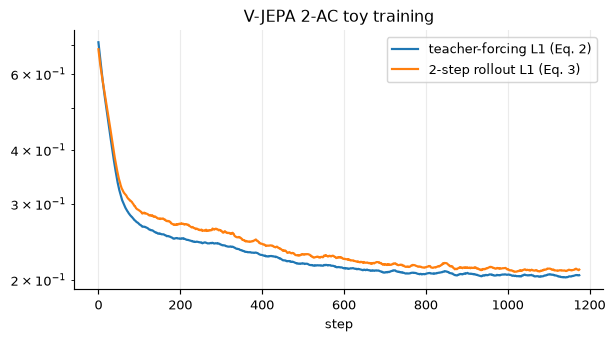

PASS AC training reduced both losses (last 100 steps < first 100)   [tf 0.445->0.205, rollout 0.453->0.211]


In [20]:
ac, ac_hist = train_ac(enc_j, steps=AC_STEPS)
tf_h = np.array([h[0] for h in ac_hist]); ro_h = np.array([h[1] for h in ac_hist])
sm = lambda x, k=25: np.convolve(x, np.ones(k) / k, mode="valid")
plt.figure(figsize=(6.5, 3.2)); plt.plot(sm(tf_h), label="teacher-forcing L1 (Eq. 2)"); plt.plot(sm(ro_h), label="2-step rollout L1 (Eq. 3)"); plt.yscale("log"); plt.xlabel("step"); plt.legend(); plt.title("V-JEPA 2-AC toy training"); plt.show()
check("AC training reduced both losses (last 100 steps < first 100)", tf_h[-100:].mean() < tf_h[:100].mean() and ro_h[-100:].mean() < ro_h[:100].mean(), f"tf {tf_h[:100].mean():.3f}->{tf_h[-100:].mean():.3f}, rollout {ro_h[:100].mean():.3f}->{ro_h[-100:].mean():.3f}")

**Does the world model actually use the action?** Held-out episodes, four comparisons of the error `‖ẑ − z‖₁` against the *true* next-frame features:

1. **ours**: predictor with the true actions;
2. **shuffled actions**: same inputs but actions permuted across the batch - if the model ignores actions this changes nothing;
3. **copy-last**: predict `z_{k+1} = z_k` ("nothing moves");
4. **noise floor**: re-encode the *same* scene and position with a fresh draw of pixel noise - the error nobody can avoid.

Then **autoregressive rollouts** for 1-4 steps (feeding predictions back in, states updated by `s ← s + a`), because planning needs multi-step predictions and the paper warns that error accumulates.

1-step L1 error vs true next features ->  ours 0.2046 | shuffled actions 0.2524 | copy-last 0.2770 | noise floor 0.2231
PASS world model beats 'nothing moves' (copy-last)   [0.2046 < 0.2770]
PASS world model USES the action: shuffling actions makes it worse   [0.2524 vs 0.2046]


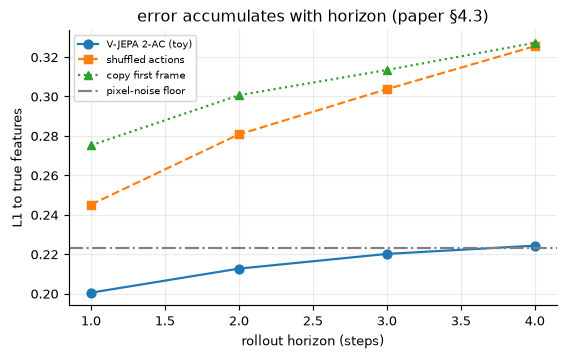

rollout error by horizon: [0.2005, 0.2127, 0.2201, 0.2243]
PASS autoregressive error grows with horizon (h=4 > h=1)
PASS multi-step rollouts still beat copy-first-frame at every horizon


In [21]:
@torch.no_grad()
def ar_rollout(ac, z0, a, s0, nsteps):                         # a (B,nsteps,2) px ; returns predicted z_1..z_n  (B,n,NP,D)
    zs = [z0[:, None]]; s = s0; ss = [s0]
    for k in range(nsteps):
        Z = torch.cat(zs, 1); S = torch.stack(ss, 1)
        zn = ac(Z, a[:, :k + 1] / R_ACT, sn(S))[:, -1]; zs.append(zn[:, None]); s = s + a[:, k]; ss.append(s)
    return torch.cat(zs[1:], 1)

torch.manual_seed(123); Be = 128; sc = Scene(Be); pos, a = episode(Be, 4); z = encode(enc_j, sc, pos)
with torch.no_grad():
    tf_err = (ac(z[:, :4], a / R_ACT, sn(pos[:, :4])) - z[:, 1:]).abs().mean().item()
    perm = torch.randperm(Be); sh_err = (ac(z[:, :4], a[perm] / R_ACT, sn(pos[:, :4])) - z[:, 1:]).abs().mean().item()
cp_err = (z[:, :4] - z[:, 1:]).abs().mean().item()
z_noise = encode(enc_j, sc, pos)                                  # same scene+positions, fresh pixel noise
floor = (z - z_noise).abs().mean().item()
print(f"1-step L1 error vs true next features ->  ours {tf_err:.4f} | shuffled actions {sh_err:.4f} | copy-last {cp_err:.4f} | noise floor {floor:.4f}")
check("world model beats 'nothing moves' (copy-last)", tf_err < cp_err, f"{tf_err:.4f} < {cp_err:.4f}")
check("world model USES the action: shuffling actions makes it worse", sh_err > tf_err * 1.05, f"{sh_err:.4f} vs {tf_err:.4f}")
Hs = [1, 2, 3, 4]; E_ours, E_sh, E_cp = [], [], []
pred_roll = ar_rollout(ac, z[:, 0], a, pos[:, 0], 4); pred_sh = ar_rollout(ac, z[:, 0], a[perm], pos[:, 0], 4)
for h in Hs:
    E_ours.append((pred_roll[:, h - 1] - z[:, h]).abs().mean().item()); E_sh.append((pred_sh[:, h - 1] - z[:, h]).abs().mean().item()); E_cp.append((z[:, 0] - z[:, h]).abs().mean().item())
plt.figure(figsize=(6, 3.4)); plt.plot(Hs, E_ours, "o-", label="V-JEPA 2-AC (toy)"); plt.plot(Hs, E_sh, "s--", label="shuffled actions"); plt.plot(Hs, E_cp, "^:", label="copy first frame"); plt.axhline(floor, color="gray", ls="-.", label="pixel-noise floor")
plt.xlabel("rollout horizon (steps)"); plt.ylabel("L1 to true features"); plt.legend(fontsize=7); plt.title("error accumulates with horizon (paper §4.3)"); plt.show()
print("rollout error by horizon:", [round(e, 4) for e in E_ours])
check("autoregressive error grows with horizon (h=4 > h=1)", E_ours[-1] > E_ours[0])
check("multi-step rollouts still beat copy-first-frame at every horizon", all(o < c for o, c in zip(E_ours, E_cp)))

## Step 11 - Planning: actions from a goal *image* 🎯

Now the payoff. Given a **goal image** `x_g`, we don't train a policy; we **search** for actions by imagining. With current features `z_k`, state `s_k`, goal features `z_g = E(x_g)` and horizon `T`, define the **energy** (Eq. 5):

`E(â_{1:T}; z_k, s_k, z_g) = ‖ P_φ(â_{1:T}; s_k, z_k) − z_g ‖₁`

and solve `a* = argmin E` with the **Cross-Entropy Method** (Rubinstein 1997):

1. keep an independent Gaussian per action coordinate per time step, initialised **mean 0, variance 1**;
2. sample many action sequences, project each action into the **L1-ball** (paper: radius 0.075 → ≤ 13 cm per step, since larger actions are out-of-distribution);
3. score each by the energy (an imagined rollout of the world model);
4. refit the Gaussians to the **top-k** sequences; repeat a few iterations; return the **mean**.

Then **execute only the first action**, observe the new frame, and **re-plan** - *model-predictive control* with a receding horizon (so imperfect predictions get corrected by feedback).

<p align="center"><img src="images/p_fig7_planning.png" width="900"><br><sub>Fig. 7 (paper) - current frame and goal frame are encoded by the frozen encoder; the action-conditioned predictor imagines the future from sampled action sequences; the L1 distance between the imagined and goal features is the cost.</sub></p>

**Why latent planning is fast.** The world model predicts *features*, not pixels. The paper's Table 3: with 800 samples, 10 CEM iterations and horizon 1, V-JEPA 2-AC needs **16 s per action** vs **4 min** for the Cosmos video-diffusion world model (80 samples, 10 iterations, horizon 1) - and succeeds more often.

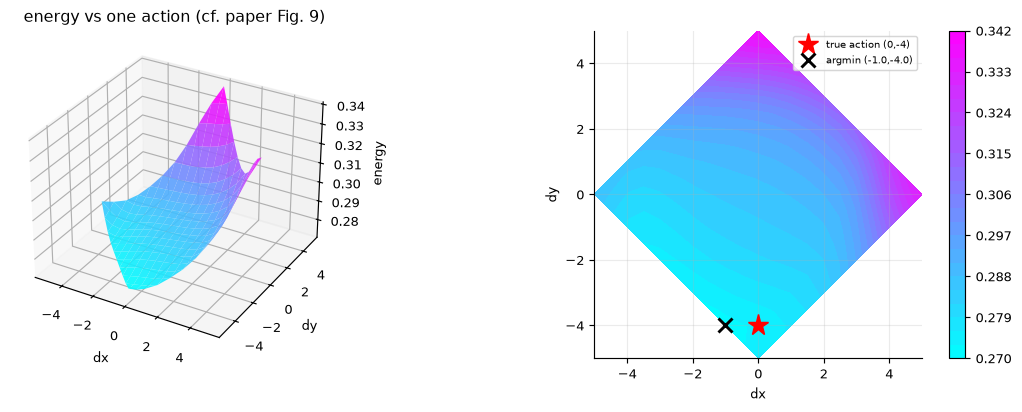

energy minimiser is 1.00 px from the true action (max action size 5.0 px)
PASS energy landscape minimum is close to the ground-truth action (< 2.5 px)   [1.00px]


Spearman correlation between latent energy and true distance-to-goal after the action: 0.82
PASS latent energy is rank-correlated with the true distance to the goal (rho > 0.5)   [rho=0.82]


In [22]:
@torch.no_grad()
def rollout_energy(ac, z0, s0, acts, zg):                        # z0 (n,NP,D) s0 (n,2) acts (n,Hh,2) px ; zg (NP,D) -> Eq.5 energy (n,)
    n, Hh, _ = acts.shape; zs = [z0[:, None]]; ss = [s0]; s = s0
    for k in range(Hh):
        zn = ac(torch.cat(zs, 1), acts[:, :k + 1] / R_ACT, sn(torch.stack(ss, 1)))[:, -1]; zs.append(zn[:, None]); s = s + acts[:, k]; ss.append(s)
    return (zs[-1][:, 0] - zg[None]).abs().mean((1, 2))

@torch.no_grad()
def cem(ac, z0, s0, zg, Hh=3, n=150, topk=15, iters=4):
    mu = torch.zeros(Hh, 2); sd = torch.ones(Hh, 2)                     # Gaussians: mean 0, variance 1 (normalised units)
    for _ in range(iters):
        a = proj_l1(mu + sd * torch.randn(n, Hh, 2)) * R_ACT           # sample, project to L1 ball, scale to px
        E = rollout_energy(ac, z0[None].expand(n, -1, -1), s0[None].expand(n, -1), a, zg)
        el = a[E.topk(topk, largest=False).indices] / R_ACT; mu = el.mean(0); sd = el.std(0) + 1e-3   # refit to the top-k trajectories
    return proj_l1(mu) * R_ACT, E.min().item()                          # return the MEAN as the plan

def mpc(enc, ac, start, goal, sc, steps=8, Hh=3, policy="cem"):
    pos = start.clone(); traj = [pos.clone()]; zg = encode(enc, sc, goal[None, None])[0, 0]
    for _ in range(steps):
        if policy == "cem": z0 = encode(enc, sc, pos[None, None])[0, 0]; plan, _ = cem(ac, z0, pos, zg, Hh=Hh); act = plan[0]   # plan H steps, EXECUTE ONLY THE FIRST
        elif policy == "random": act = proj_l1(torch.randn(2)) * R_ACT * float(torch.rand(1))
        else: act = torch.zeros(2)
        pos = (pos + act).clamp(8, 40); traj.append(pos.clone())
    return torch.stack(traj)

# ---------- Fig. 9 analogue: the energy landscape over a single action ----------
torch.manual_seed(7); sc1 = Scene(1); p0 = torch.tensor([24.0, 24.0]); g = torch.tensor([24.0, 20.0])           # goal = 4 px up
z0 = encode(enc_j, sc1, p0[None, None])[0, 0]; zg = encode(enc_j, sc1, g[None, None])[0, 0]
ax_ = torch.linspace(-R_ACT, R_ACT, 21); DX, DY = torch.meshgrid(ax_, ax_, indexing="ij"); A = torch.stack([DX.reshape(-1), DY.reshape(-1)], -1)[:, None, :]
Eg = rollout_energy(ac, z0[None].expand(len(A), -1, -1), p0[None].expand(len(A), -1), A, zg).reshape(21, 21)
valid = (DX.abs() + DY.abs()) <= R_ACT + 1e-6; Em = torch.where(valid, Eg, torch.full_like(Eg, float("inf"))); i = int(Em.argmin()); best = (DX.reshape(-1)[i].item(), DY.reshape(-1)[i].item())
fig = plt.figure(figsize=(11, 4)); ax3 = fig.add_subplot(1, 2, 1, projection="3d"); ax3.plot_surface(DX.numpy(), DY.numpy(), torch.where(valid, Eg, torch.tensor(float("nan"))).numpy(), cmap="cool", alpha=.9); ax3.set_xlabel("dx"); ax3.set_ylabel("dy"); ax3.set_zlabel("energy"); ax3.set_title("energy vs one action (cf. paper Fig. 9)")
ax2 = fig.add_subplot(1, 2, 2); im = ax2.contourf(DX, DY, torch.where(valid, Eg, torch.tensor(float("nan"))), 25, cmap="cool"); plt.colorbar(im, ax=ax2); ax2.plot(0, -4, "r*", ms=15, label="true action (0,-4)"); ax2.plot(*best, "kx", ms=10, mew=2, label=f"argmin ({best[0]:.1f},{best[1]:.1f})"); ax2.legend(fontsize=7); ax2.set_xlabel("dx"); ax2.set_ylabel("dy"); ax2.set_aspect("equal"); plt.tight_layout(); plt.show()
err_act = math.hypot(best[0] - 0, best[1] + 4); print(f"energy minimiser is {err_act:.2f} px from the true action (max action size {R_ACT} px)")
check("energy landscape minimum is close to the ground-truth action (< 2.5 px)", err_act < 2.5, f"{err_act:.2f}px")
# does latent L1 track real distance-to-goal? (rank correlation over random actions)
a_r = proj_l1(torch.randn(600, 1, 2) * 1.5) * R_ACT; E_r = rollout_energy(ac, z0[None].expand(600, -1, -1), p0[None].expand(600, -1), a_r, zg)
d_r = ((p0[None] + a_r[:, 0]) - g[None]).norm(dim=1); rk = lambda x: x.argsort().argsort().float()
rho = torch.corrcoef(torch.stack([rk(E_r), rk(d_r)]))[0, 1].item(); print(f"Spearman correlation between latent energy and true distance-to-goal after the action: {rho:.2f}")
check("latent energy is rank-correlated with the true distance to the goal (rho > 0.5)", rho > 0.5, f"rho={rho:.2f}")

policy     mean final dist (px)   success (<2.5 px)   (mean start distance 7.8px)
cem                        1.64                 71%
random                     7.96                  4%
zero                       7.79                  0%
PASS planning with the latent world model reaches goal images far more often than random/zero actions   [cem 71% vs random 4%, zero 0%]


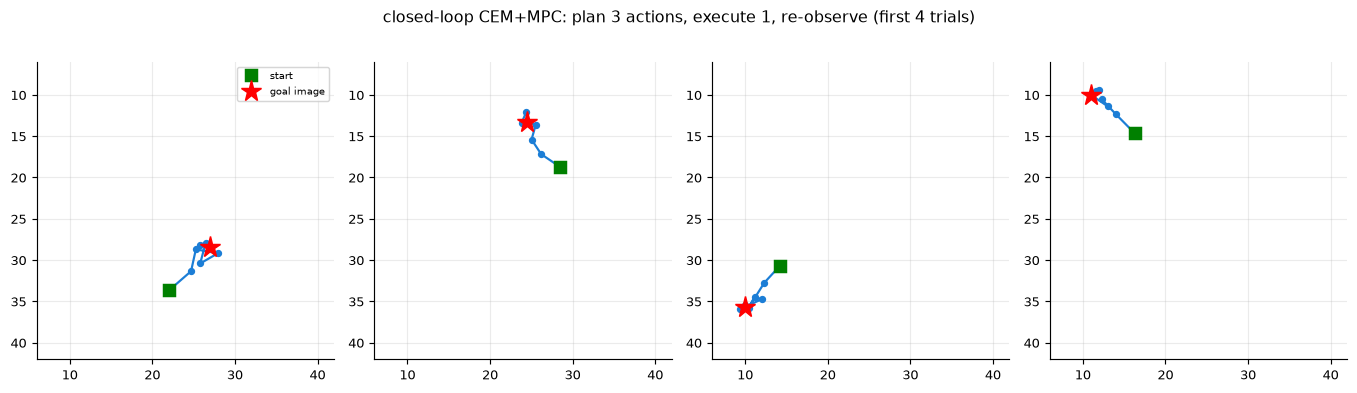

In [23]:
# ---------- closed-loop MPC: reach a goal image ----------
torch.manual_seed(2024); NTR = 24; res = {"cem": [], "random": [], "zero": []}; trajs = []
for tr in range(NTR):
    scn = Scene(1); st0 = torch.empty(2).uniform_(14, 34); off = proj_l1(torch.randn(2) * 2, 1.0) * 10.0 + torch.randn(2) * 0.5
    off = off * (12.0 / max(12.0, off.abs().sum().item())); goal = (st0 + off).clamp(10, 38)
    for pol in res:
        tj = mpc(enc_j, ac, st0, goal, scn, steps=6, Hh=3, policy=pol); res[pol].append(((tj[-1] - goal).norm().item(), (tj[0] - goal).norm().item()))
        if pol == "cem" and tr < 4: trajs.append((tj, goal))
print(f"{'policy':8s} {'mean final dist (px)':>22s} {'success (<2.5 px)':>19s}   (mean start distance {np.mean([r[1] for r in res['cem']]):.1f}px)")
SR = {}
for pol, r in res.items():
    fin = np.array([x[0] for x in r]); SR[pol] = (fin < 2.5).mean(); print(f"{pol:8s} {fin.mean():22.2f} {100 * SR[pol]:18.0f}%")
check("planning with the latent world model reaches goal images far more often than random/zero actions", SR["cem"] > max(SR["random"], SR["zero"]) + 0.3, f"cem {SR['cem']:.0%} vs random {SR['random']:.0%}, zero {SR['zero']:.0%}")
fig, axs = plt.subplots(1, 4, figsize=(13, 3.4))
for ax, (tj, goal) in zip(axs, trajs):
    ax.plot(tj[:, 0], tj[:, 1], "o-", color="#1c7ed6", ms=4); ax.plot(*tj[0], "gs", ms=8, label="start"); ax.plot(*goal, "r*", ms=15, label="goal image"); ax.set_xlim(6, 42); ax.set_ylim(42, 6); ax.set_aspect("equal")
axs[0].legend(fontsize=7); plt.suptitle("closed-loop CEM+MPC: plan 3 actions, execute 1, re-observe (first 4 trials)", y=1.02); plt.tight_layout(); plt.show()

## Step 12 - What the paper reports (paper scale), limits, and what came next 📊

Everything above is a miniature. These are the **paper's own numbers** (all quoted from the paper's tables; nothing here is re-measured).

**Understanding** (frozen encoder + attentive probe, Table 4):

| model | params | SSv2 | Diving-48 | Jester | K400 | COIN | IN1K | avg |
|---|---|---|---|---|---|---|---|---|
| DINOv2 | 1.1 B | 50.7 | 82.5 | 93.4 | 83.6 | 90.7 | 86.1 | 81.1 |
| PE-core G | 1.9 B | 55.4 | 76.9 | 90.0 | 88.5 | 95.3 | 87.6 | 82.3 |
| V-JEPA (v1) ViT-H | 0.6 B | 74.3 | 87.9 | 97.7 | 84.5 | 87.1 | 80.0 | 85.2 |
| V-JEPA 2 ViT-g | 1 B | 75.3 | 90.1 | 97.7 | 86.6 | 90.7 | 84.6 | 87.5 |
| V-JEPA 2 ViT-g384 | 1 B | **77.3** | **90.2** | **97.8** | 87.3 | 91.1 | 85.1 | **88.2** |

Strongest on **motion** (SSv2, Diving, Jester), competitive on **appearance** - exactly what a model trained to predict *dynamics* should be.

**Prediction** - Epic-Kitchens-100 action anticipation (recall@5, Table 5): V-JEPA 2 ViT-g384 reaches **39.7** on *action* (verb 63.6, noun 57.1) vs PlausiVL 27.6 and InAViT 25.8 - a 44 % relative improvement - using a frozen encoder+predictor and a probe.

<p align="center"><img src="images/p_fig11_ek100.png" width="820"><br><sub>Fig. 11 (paper) - EK100 anticipation: context frames → top-5 predicted actions → what happened 1 s later. Two successes, one failure.</sub></p>

**Video QA** (encoder aligned to an 8 B LLM, no language supervision in the encoder): PerceptionTest **84.0**, MVP **44.5**, TempCompass **76.9**, TemporalBench **36.7**, TOMATO **40.3**.

**Planning** (zero-shot, two labs not in Droid, Table 2): 

| task | Octo (avg of 2 labs) | V-JEPA 2-AC (avg of 2 labs) |
|---|---|---|
| Reach | 100 % | 100 % |
| Grasp cup / box | 15 % / 0 % | **65 % / 25 %** |
| Reach with object, cup / box | 15 % / 70 % | **75 % / 75 %** |
| Pick-and-place cup / box | 15 % / 10 % | **80 % / 65 %** |

<p align="center"><img src="images/p_fig10_pickplace.png" width="820"><br><sub>Fig. 10 (paper) - closed-loop pick-and-place with three goal images; highlighted frames mark when a sub-goal is reached and the next goal takes over.</sub></p>

**Limits the authors state (§4.3):** (1) **camera sensitivity** - the model must infer the action axes from a monocular image; when the robot base isn't visible this is ill-posed, and they hand-tuned the camera position; (2) **long-horizon planning** - autoregressive errors accumulate and the search space grows exponentially with horizon, so pick-and-place needed *image sub-goals*; (3) **goals are images** - language goals would need aligning the latent world model with a language model.

**What came next.** The official repository's README (accessed while preparing this notebook) lists **V-JEPA 2.1** (dated 2026-03-16): a recipe with a *dense predictive loss* (all tokens, visible and masked, contribute), *deep self-supervision* at intermediate layers, and multi-modal tokenizers, aimed at higher-quality, temporally consistent **dense** features. We did not read that paper; the image below is the repo's own PCA teaser.

<p align="center"><img src="images/web_vjepa21_pca.png" width="820"><br><sub>V-JEPA 2.1 PCA feature visualisation, from facebookresearch/vjepa2 (MIT licence). Not covered by this notebook's experiments.</sub></p>

In [24]:
print(f"{'#':>2s}  {'status':6s}  check")
for i, (n_, ok, d_) in enumerate(CHECKS, 1): print(f"{i:2d}  {'PASS' if ok else 'FAIL':6s}  {n_}")
failed = [n_ for n_, ok, _ in CHECKS if not ok]; print(f"\n{len(CHECKS) - len(failed)} passed, {len(failed)} failed")
assert not failed, failed

 #  status  check
 1  PASS    unpredictable noise carries more pixel energy than the object whose motion we care about
 2  PASS    most of the pixel loss is irreducible noise: even a wrong-trajectory guess pays >50% noise floor
 3  PASS    Conv3d patch embed == unfold tubelets + one shared linear layer
 4  PASS    16x256x256 clip -> 2048 tokens (paper's 16-frame / 256 px setting)
 5  PASS    64x384x384 clip -> 18432 tokens
 6  PASS    RoPE: score(q at t, k at t+2) is the same for t=3, 10, 100 (depends only on offset)
 7  PASS    RoPE: ...but changes when the offset changes
 8  PASS    3D-RoPE: translating the whole clip in (t,h,w) leaves attention scores unchanged
 9  PASS    keep and pred are disjoint and cover every token
10  PASS    all samples have the same number of masked tokens (batchable)
11  PASS    holes span the full temporal extent (same spatial positions at every time layer)
12  PASS    encoder on visible tokens returns Nv vectors of dim D
13  PASS    ViT-L: counted params

## The whole thing in one page

```
STAGE 1  pre-train (no actions, no labels)                          STAGE 2  post-train (62 h robot video, encoder frozen)
video ─tubelets 2x16x16─▶ tokens ─mask 90 %─▶ ENCODER(visible)       frames ─▶ frozen ENCODER ─▶ z_k
                                   │                                  [a_k, s_k, z_k] interleaved ─▶ PREDICTOR (block-causal) ─▶ ẑ_{k+1}
        PREDICTOR(visible feats + mask tokens) ─▶ ẑ_masked              loss = |ẑ_{k+1}-z_{k+1}|₁  (teacher forcing) + 2-step rollout
        target = sg( LN( EMA-ENCODER(full video) ) )                  PLAN: argmin_a |P(a; z, s) - z_goal|₁  by CEM, execute first action, repeat
        loss = L1 on masked tokens only
```

### Key takeaways
1. **Predict in representation space.** The target is another encoder's output, so the model is free to ignore unpredictable pixel detail (Step 1, and the noise-vs-motion measurement in Step 8).
2. **Collapse is the central failure mode**; EMA teacher + stop-gradient (+ layer-normed targets) is what keeps it away (Step 7-8).
3. **Mask big, mask all frames.** Large multi-block holes through the whole clip force real inference about motion (Step 4).
4. **Scaling = data × model × schedule × resolution**, made affordable by warmup-constant-cooldown and a *late* resolution increase (Step 9).
5. **A world model is a predictor you can search through.** Freeze the encoder, learn `P(next features | history, action)` from little data, then plan by minimising a feature-space distance to a goal image (Steps 10-11).

### Exercises
1. Replace L1 with L2 in `jepa_loss` and compare `feat-std` and the probe accuracy.
2. Raise the mask ratio (more/larger blocks) and lower it (random tubes: mask individual tokens). Which gives the better frozen probe?
3. Remove layer-norm from the target (Step 7). Does the loss scale matter? Does collapse come back?
4. In Step 10 drop the rollout loss (Eq. 3). Does the 4-step error grow faster?
5. Planning: increase the horizon to 6 with the same CEM budget. How does success change? Relate it to the paper's "long-horizon planning" limitation.
6. Replace the blob-position action with a *noisy* action effect (random slippage) and see how CEM+MPC's closed loop compensates.

### Honest limits of this notebook
- **Toy scale.** A 0.5 M-parameter encoder on synthetic 48×48 videos of one moving blob. It demonstrates mechanisms (masking, EMA, collapse, block-causal AC predictor, CEM+MPC), **not** the paper's accuracy, and none of the paper's results are reproduced here.
- Hyper-parameters differ from the paper where scale demands it: tubelet `2×8×8`, mask ≈ one third (paper ≈ 90 %), EMA 0.99 (paper 0.99925), equal-size mask trimming across the batch, batch 32 (paper 3072).
- The 7-D end-effector state/action is replaced by a 2-D position/displacement; the encoder sees a single frame duplicated into a 2-frame clip, and planning uses a fixed small L1 radius in pixels.
- **The direction probe is a negative result** (trained 16 % vs random-init 62.5 %); we did not find a toy configuration where the trained encoder wins, and we did not tune for one. The explanation we measured only partly (29 % of feature variance is positional) and did not establish.
- Probe results here use a **single seed** and small test sets; differences of a few points are within noise. Collapse/no-collapse is the robust effect.
- The FLOP comparison in Step 9 is a back-of-envelope estimate (no masking, no hardware effects); the paper's own GPU-time figures should be preferred.
- The target layer-norm and the equal-size-mask trick are taken from the official code, not from the paper text. The V-JEPA 2.1 paragraph is based only on the repository README.

### References
- Assran et al. 2025, *V-JEPA 2*, arXiv:2506.09985 · Bardes et al. 2024, *V-JEPA*, arXiv:2404.08471 · Assran et al. 2023, *I-JEPA*, arXiv:2301.08243 · LeCun 2022, *A path towards autonomous machine intelligence*.
- Dosovitskiy et al. 2020, *ViT*, arXiv:2010.11929 · He et al. 2021, *MAE*, arXiv:2111.06377 · Su et al. 2021, *RoFormer (RoPE)*, arXiv:2104.09864 · Grill et al. 2020, *BYOL*, arXiv:2006.07733 · Rubinstein 1997, *Cross-Entropy Method*.
- Code: github.com/facebookresearch/vjepa2 (MIT). Figures credited in their captions.